In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==========================================
# 3.1 IMPORT ALL REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from scipy.stats import rankdata

In [ ]:
# Base path (YOUR REQUIRED FOLDER)
base_path = "/content/drive/MyDrive/RE2"

folders = [
    "figures",
    "tables",
    "models",
    "checkpoints",
    "pdf_assets"
]

for f in folders:
    os.makedirs(os.path.join(base_path, f), exist_ok=True)

print("Project directories created inside RE2")

Project directories created inside RE2


In [ ]:
#LOAD DATASET (FROM RE2)
df = pd.read_csv(base_path + "/Dataset.csv")

print("Shape:", df.shape)
df.head()

Shape: (1552210, 44)


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072


In [ ]:
df = df.drop(columns=['Unnamed: 0'])

In [ ]:
#SORT + 6-HOUR EARLY PREDICTION
df = df.sort_values(['Patient_ID','Hour'])

# ✅ FIXED: 6-hour prediction
df['SepsisLabel_e'] = df.groupby('Patient_ID')['SepsisLabel'].shift(-6)

df = df.dropna(subset=['SepsisLabel_e'])

In [ ]:
# ==========================================
# TABLE 1 — DATASET CHARACTERISTICS
# ==========================================

print("Total Samples:", df.shape[0])
print("Total Features:", df.shape[1])
print("Unique Patients:", df['Patient_ID'].nunique())

print(df['SepsisLabel'].value_counts())

Total Samples: 1310194
Total Features: 44
Unique Patients: 40336
SepsisLabel
0    1299829
1      10365
Name: count, dtype: int64


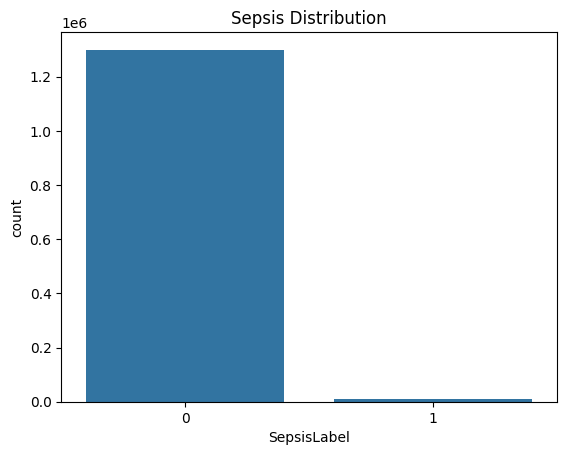

In [ ]:
#SAVE CLASS DISTRIBUTION FIGURE
plt.figure()
sns.countplot(x='SepsisLabel', data=df)
plt.title("Sepsis Distribution")

plt.savefig(base_path + "/figures/class_distribution.png")

plt.savefig(
    base_path + "/figures/class_distribution.pdf",
    bbox_inches="tight"
)
plt.show()

In [ ]:
#TABLE 2 — SUMMARY STATISTICS
# ==========================================

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hour,1310194.0,23.739911,29.530710,0.00,8.00,17.00,29.0000,329.00
HR,1185364.0,84.674896,17.417256,20.00,72.00,84.00,96.0000,280.00
O2Sat,1147307.0,97.262246,2.867904,20.00,96.00,98.00,100.0000,100.00
Temp,451701.0,36.975767,0.774996,20.90,36.50,37.00,37.5000,50.00
SBP,1129452.0,123.613224,23.267676,20.00,106.50,121.00,138.0000,300.00
MAP,1154990.0,82.337177,16.312308,20.00,71.00,80.00,92.0000,300.00
DBP,913489.0,63.711174,13.914761,20.00,54.00,62.00,72.0000,300.00
Resp,1113978.0,18.673732,5.120366,1.00,15.00,18.00,21.0000,100.00
EtCO2,52673.0,33.011315,7.874608,10.00,28.50,33.00,38.0000,100.00
BaseExcess,77427.0,-0.716846,4.219443,-32.00,-3.00,0.00,1.0000,100.00


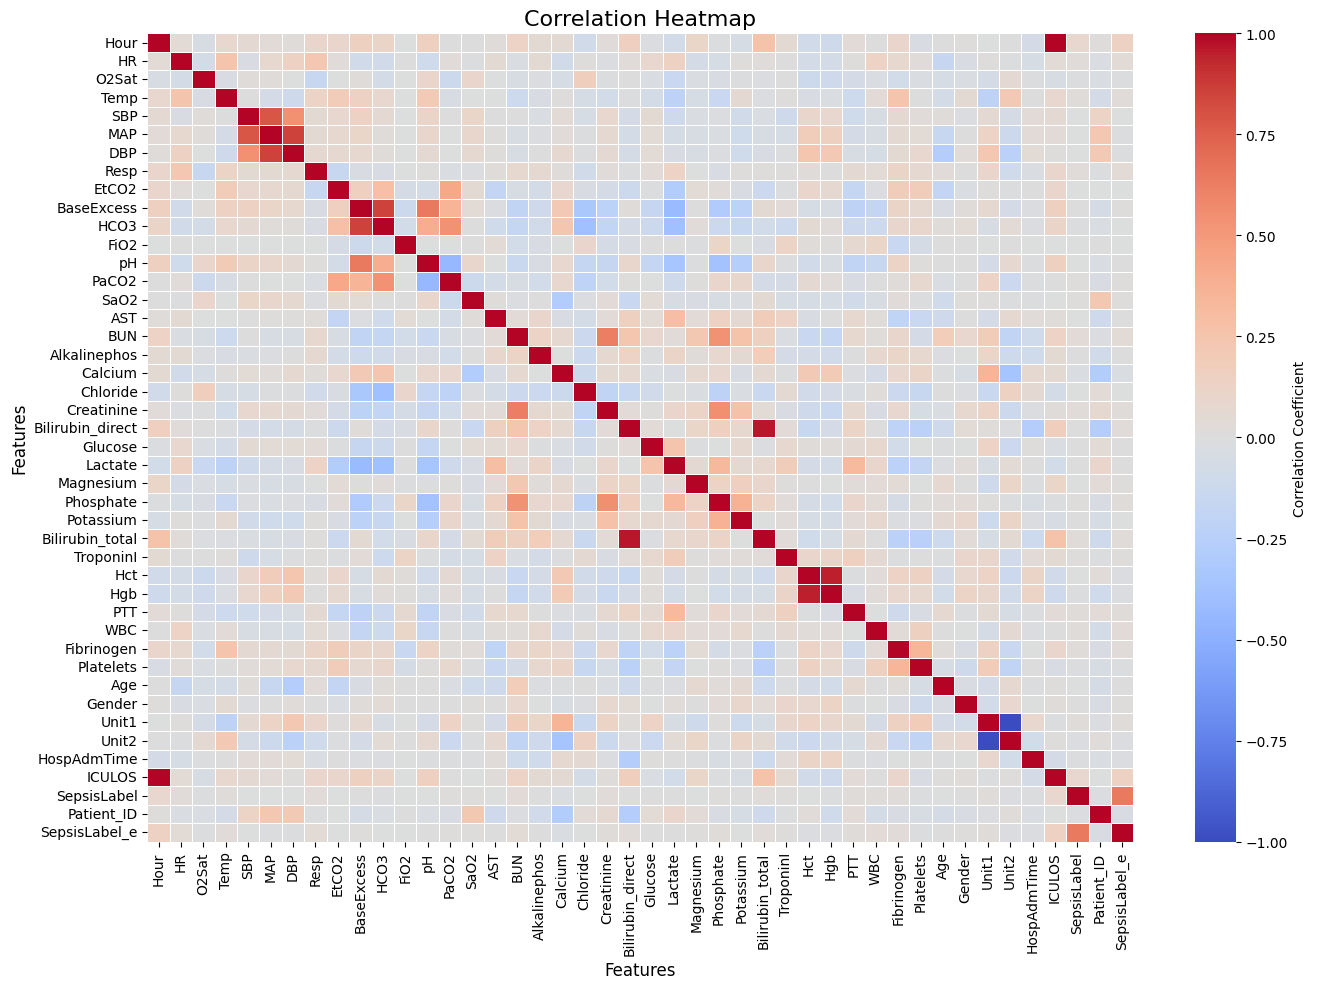

In [ ]:
# ==========================================
# CORRELATION MATRIX (FIGURE 1)
# ==========================================

plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap='coolwarm',
    annot=False,
    linewidths=0.5,
    cbar=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title("Correlation Heatmap", fontsize=16)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(base_path + "/figures/correlation_heatmap.png", dpi=300)

plt.savefig(
    base_path + "/figures/correlation_heatmap.pdf",
    bbox_inches="tight"
)
plt.show()

In [ ]:
#preprocessing
# ==========================================
# MISSING VALUES ANALYSIS
# ==========================================

missing = df.isnull().mean()*100
print(missing.sort_values(ascending=False))

Bilirubin_direct    99.793389
Fibrinogen          99.279420
TroponinI           98.967329
Bilirubin_total     98.393520
Alkalinephos        98.268959
AST                 98.251633
Lactate             97.078219
PTT                 96.835202
SaO2                96.237427
EtCO2               95.979756
Phosphate           95.744523
HCO3                95.568290
Chloride            95.188422
BaseExcess          94.090417
PaCO2               93.931662
Calcium             93.735737
Platelets           93.684599
Creatinine          93.546757
Magnesium           93.347397
WBC                 93.198641
BUN                 92.726344
pH                  92.486151
Hgb                 92.152307
FiO2                90.987213
Hct                 90.588035
Potassium           90.115510
Glucose             82.177754
Temp                65.524113
Unit2               39.555822
Unit1               39.555822
DBP                 30.278340
Resp                14.976103
SBP                 13.795056
O2Sat     

In [ ]:
#MISSINGNESS INDICATORS (IMPORTANT ADDITION)
missing_percent = df.isnull().mean()

missing_cols = missing_percent[missing_percent > 0.05].index

for col in missing_cols:
    df[col + "_missing"] = df[col].isnull().astype(int)

# Save table
missing_percent.to_csv(base_path + "/tables/missing_percentage.csv")
print("Missing indicators added:", len(missing_cols))


Missing indicators added: 36


In [ ]:
#DROP EXTREME MISSING FEATURES
df = df[df.columns[df.isnull().mean() < 0.25]]

In [ ]:
#GENDER ENCODING
# Apply BEFORE split but safe because deterministic (no leakage)

if 'Gender' in df.columns:
    df['Gender'] = LabelEncoder().fit_transform(df['Gender'].astype(str))

In [ ]:
#FEATURE / TARGET SPLIT
X = df.drop(['SepsisLabel','SepsisLabel_e','Patient_ID'], axis=1)
y = df['SepsisLabel_e']
groups = df['Patient_ID']

In [ ]:
#PATIENT-WISE SPLIT (NO LEAKAGE)
split = GroupShuffleSplit(test_size=0.2, random_state=42)

train_idx, test_idx = next(split.split(X, y, groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()


groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

In [ ]:
#IMPUTATION (TRAIN ONLY)
imputer = SimpleImputer(strategy='median')

# ✅ FIT ONLY ON TRAIN
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
# ✅ TRANSFORM TEST
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

# checkpoint save
import joblib
joblib.dump(imputer, base_path + "/checkpoints/imputer.pkl")

['/content/drive/MyDrive/RE2/checkpoints/imputer.pkl']

In [ ]:
#LOG TRANSFORMATION
skew_cols = ['MAP','BUN','Creatinine','Glucose','WBC','Platelets']

for col in skew_cols:
    if col in X_train.columns:
        X_train[col] = np.log1p(X_train[col])
        X_test[col] = np.log1p(X_test[col])

In [ ]:
#COPULA TRANSFORMATION
def copula_transform(x):
    return rankdata(x) / (len(x) + 1)

copula_cols = ['HR','MAP','SBP','O2Sat','Resp']

for col in copula_cols:
    if col in X_train.columns:
        X_train[col + "_copula"] = copula_transform(X_train[col])
        X_test[col + "_copula"] = copula_transform(X_test[col])

In [ ]:
#SCALING
scaler = StandardScaler()

X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

joblib.dump(scaler, base_path + "/checkpoints/scaler.pkl")

['/content/drive/MyDrive/RE2/checkpoints/scaler.pkl']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [ ]:
X_train.to_csv(base_path + "/tables/X_train.csv", index=False)
X_test.to_csv(base_path + "/tables/X_test.csv", index=False)
X_val.to_csv(base_path + "/tables/X_val.csv", index=False)

y_train.to_csv(base_path + "/tables/y_train.csv", index=False)
y_test.to_csv(base_path + "/tables/y_test.csv", index=False)
y_val.to_csv(base_path + "/tables/y_val.csv", index=False)

In [ ]:

# =========================
# PATIENT-WISE SUBSAMPLING (TRAIN ONLY)
# =========================

from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(test_size=0.3, random_state=42)

train_idx, _ = next(
    gss.split(X_train, y_train, groups=groups.iloc[X_train.index])
)

X_train_small = X_train.iloc[train_idx].copy()
y_train_small = y_train.iloc[train_idx].copy()

print("Reduced Train Shape:", X_train_small.shape)

Reduced Train Shape: (588880, 51)


In [ ]:
print(y_train_small.value_counts())

SepsisLabel_e
0.0    577754
1.0     11126
Name: count, dtype: int64


In [ ]:
#INSTALL (IF NOT INSTALLED)
!pip install xgboost lightgbm imbalanced-learn -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [ ]:
#METRICS FUNCTION
def compute_metrics(model, X_test, y_test):

    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:,1]

    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)

    return {
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds,zero_division=0),
        "recall": recall_score(y_test, preds,zero_division=0),
        "f1": f1_score(y_test, preds,zero_division=0),
        "roc_auc": roc_auc_score(y_test, probs),
        "specificity": specificity,
        "sensitivity": sensitivity
    }

In [ ]:
#MODELS (UPDATED SOTA SET)
models = {
    "LR": LogisticRegression(max_iter=1000),
    "RF": RandomForestClassifier(n_estimators=200),
    "GB": GradientBoostingClassifier(),
    "XGB": XGBClassifier(eval_metric='logloss'),
    "LGBM": LGBMClassifier()
}

In [ ]:
#IMBALANCE STRATEGIES (NOW COMPLETE)
strategies = {
    "No_Balance": (X_train, y_train),

    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),

    "UnderSampling": RandomUnderSampler(random_state=42)
}



In [ ]:
# ADD THESE LIBRARIES
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
import json

In [ ]:
#HYPERPARAMETER GRIDS
param_grids = {

    "LR": {
        "C": [0.01, 0.1, 1],
        "solver": ["liblinear"]
    },

    "RF": {
        "n_estimators": [100, 200],
        "max_depth": [5, 10]
    },

    "GB": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1]
    },

    "XGB": {
        "n_estimators": [100, 200],
        "max_depth": [3, 5],
        "learning_rate": [0.05, 0.1]
    },

    "LGBM": {
        "n_estimators": [100, 200],
        "num_leaves": [31, 50],
        "learning_rate": [0.05, 0.1]
    }
}

In [ ]:
#GRID SEARCH FUNCTION (TABLE 3.6)

from sklearn.model_selection import RandomizedSearchCV

def tune_model(model, param_grid, X, y, model_name):

    random = RandomizedSearchCV(
        model,
        param_distributions=param_grid,  # same grid use hoti hai
        n_iter=8,                       # 🔥 only 8 combinations try karega
        cv=5,
        scoring='roc_auc',
        n_jobs=2,                        # 🔥 RAM safe
        random_state=42
    )

    random.fit(X, y)

    print(f"\nBest Params for {model_name}: {random.best_params_}")

    return random.best_estimator_, random.best_params_

In [ ]:
def check_overfitting(model, X_train, y_train, X_val, y_val):



    train_score = model.score(X_train, y_train)
    val_score = model.score(X_val, y_val)

    print("Train:", train_score)
    print("Validation:", val_score)

    gap = train_score - val_score

    if gap > 0.10:
        print("⚠️ OVERFITTING")
    elif train_score < 0.6 and val_score < 0.6:
        print("⚠️ UNDERFITTING")
    else:
        print("✅ GOOD GENERALIZATION")

    return train_score, val_score


In [ ]:
#UPDATED RUN EXPERIMENT
def run_experiment(X_res, y_res, strategy_name):

    results = []
    best_params_table = []

    print(f"\n🚀 STRATEGY: {strategy_name}")
    print(f"Data Shape Used -> X: {X_res.shape}, y: {y_res.shape}")

    for model_name, model in models.items():

        save_name = f"{strategy_name}_{model_name}.pkl"
        save_path = models_path + "/" + save_name

        # =========================
        # 🔥 SKIP IF ALREADY TRAINED
        # =========================
        if os.path.exists(save_path)and os.path.getsize(save_path) > 0:
            print(f"⏩ SKIPPING {save_name} (already trained)")
            continue

        print(f"\nTUNING: {model_name} ({strategy_name})")

        # =========================
        # HYPERPARAMETER TUNING
        # =========================
        best_model, best_params = tune_model(
            model,
            param_grids[model_name],
            X_res,
            y_res,
            model_name
        )

        # =========================
        # OVERFITTING CHECK
        # =========================
        train_score, val_score = check_overfitting(
            best_model,
            X_res, y_res,
            X_val, y_val
        )

        # =========================
        # FINAL TEST EVALUATION
        # =========================
        metrics = compute_metrics(best_model, X_test, y_test)

        # =========================
        # SAVE MODEL
        # =========================

        joblib.dump(best_model, save_path)



        # =========================
        # SAVE BEST PARAMS (TABLE 3.6)
        # =========================
        best_params_table.append([
            strategy_name,
            model_name,
            str(best_params)
        ])

        print(f"\nSaved Model: {save_name}")
        print(metrics)

        # =========================
        # STORE RESULTS (TABLE 4.1)
        # =========================
        results.append([
            strategy_name,
            model_name,
            train_score,
            val_score,
            metrics["accuracy"],
            metrics["precision"],
            metrics["recall"],
            metrics["f1"],
            metrics["roc_auc"],
            metrics["specificity"],
            metrics["sensitivity"]
        ])

    return results, best_params_table


In [ ]:
# ==========================================
# COST-SENSITIVE MODELS (UPDATED FOR PAPER)
# ==========================================

neg = len(y_train[y_train == 0])
pos = len(y_train[y_train == 1])
scale_pos = neg / pos

cost_models = {

    # Logistic Regression (baseline cost-sensitive)
    "LR_Cost": LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ),

    # Random Forest (cost-sensitive)
    "RF_Cost": RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ),

    # Gradient Boosting (⚠️ no native cost handling)
    # we KEEP it only for comparison baseline
    "GB_Cost": GradientBoostingClassifier(),

    # XGBoost (proper imbalance handling)
    "XGB_Cost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=scale_pos,
        eval_metric='logloss',
        random_state=42
    ),

    # LightGBM (best practice)
    "LGBM_Cost": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        scale_pos_weight=scale_pos,
        random_state=42
    )
}

In [ ]:
import joblib
import os

models_path = base_path + "/best_models"
os.makedirs(models_path, exist_ok=True)

In [ ]:
#RUN ALL STRATEGIES
all_results = []
all_params = []

In [ ]:
# NO BALANCE (ON SUBSAMPLED DATA)
res, params = run_experiment(X_train, y_train, "No_Balance")

all_results.extend(res)
all_params.extend(params)
# UNDER SAMPLING
X_us, y_us = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_us, y_us, "UnderSampling")
all_results.extend(res)
all_params.extend(params)
# ADASYN
X_ad, y_ad = ADASYN(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_ad, y_ad, "ADASYN")
all_results.extend(res)
all_params.extend(params)
# SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_sm, y_sm, "SMOTE")
all_results.extend(res)
all_params.extend(params)



🚀 STRATEGY: No_Balance
Data Shape Used -> X: (838084, 51), y: (838084,)
⏩ SKIPPING No_Balance_LR.pkl (already trained)
⏩ SKIPPING No_Balance_RF.pkl (already trained)
⏩ SKIPPING No_Balance_GB.pkl (already trained)
⏩ SKIPPING No_Balance_XGB.pkl (already trained)
⏩ SKIPPING No_Balance_LGBM.pkl (already trained)

🚀 STRATEGY: UnderSampling
Data Shape Used -> X: (31724, 51), y: (31724,)
⏩ SKIPPING UnderSampling_LR.pkl (already trained)
⏩ SKIPPING UnderSampling_RF.pkl (already trained)
⏩ SKIPPING UnderSampling_GB.pkl (already trained)
⏩ SKIPPING UnderSampling_XGB.pkl (already trained)
⏩ SKIPPING UnderSampling_LGBM.pkl (already trained)


In [ ]:
# NO BALANCE (ON SUBSAMPLED DATA)
res, params = run_experiment(X_train, y_train, "No_Balance")

all_results.extend(res)
all_params.extend(params)
# UNDER SAMPLING
X_us, y_us = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_us, y_us, "UnderSampling")
all_results.extend(res)
all_params.extend(params)
# ADASYN
X_ad, y_ad = ADASYN(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_ad, y_ad, "ADASYN")
all_results.extend(res)
all_params.extend(params)
# SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_sm, y_sm, "SMOTE")
all_results.extend(res)
all_params.extend(params)



🚀 STRATEGY: No_Balance
Data Shape Used -> X: (838084, 51), y: (838084,)
⏩ SKIPPING No_Balance_LR.pkl (already trained)
⏩ SKIPPING No_Balance_RF.pkl (already trained)

TUNING: GB (No_Balance)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Best Params for GB: {'n_estimators': 200, 'learning_rate': 0.1}
Train: 0.981283499028737
Validation: 0.9811665656425848
✅ GOOD GENERALIZATION

Saved Model: No_Balance_GB.pkl
{'accuracy': 0.9822422112121986, 'precision': 0.19014084507042253, 'recall': 0.005901639344262295, 'f1': 0.011447954208183167, 'roc_auc': np.float64(0.8038260913617556), 'specificity': np.float64(0.9995542877518274), 'sensitivity': np.float64(0.005901639344262295)}

TUNING: XGB (No_Balance)

Best Params for XGB: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Train: 0.9812990106003694
Validation: 0.9811952023902138
✅ GOOD GENERALIZATION

Saved Model: No_Balance_XGB.pkl
{'accuracy': 0.9815034140805593, 'precision': 0.12698412698412698, 'recall': 0.010491803278688525, 'f1': 0.019382192610539067, 'roc_auc': np.float64(0.8028831374889175), 'specificity': np.float64(0.9987209996356787), 'sensitivity': np.float64(0.010491803278688525)}

TUNING: LGBM (No_Balance)
[LightGBM] [Info] Number of positive: 15862, n

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 3 is smaller than n_iter=8. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Best Params for LR: {'solver': 'liblinear', 'C': 0.01}
Train: 0.6948051948051948
Validation: 0.7731062757432429
✅ GOOD GENERALIZATION

Saved Model: UnderSampling_LR.pkl
{'accuracy': 0.7723590858718378, 'precision': 0.047169037423504125, 'recall': 0.6284153005464481, 'f1': 0.08775142691450721, 'roc_auc': np.float64(0.7565811979279643), 'specificity': np.float64(0.7749114389141675), 'sensitivity': np.float64(0.6284153005464481)}

TUNING: RF (UnderSampling)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


... (4 outputs left out)


Best Params for LR: {'solver': 'liblinear', 'C': 0.01}
Train: 0.6758562132985096
Validation: 0.7532514640537226
✅ GOOD GENERALIZATION

Saved Model: ADASYN_LR.pkl
{'accuracy': 0.7513109840853958, 'precision': 0.04427567989433872, 'recall': 0.644808743169399, 'f1': 0.08286167717652346, 'roc_auc': np.float64(0.7547178703947144), 'specificity': np.float64(0.7531994387901432), 'sensitivity': np.float64(0.644808743169399)}

TUNING: RF (ADASYN)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Best Params for RF: {'n_estimators': 200, 'max_depth': 10}
Train: 0.8075433382892971
Validation: 0.8930656115616096
✅ GOOD GENERALIZATION

Saved Model: ADASYN_RF.pkl
{'accuracy': 0.7972192285282323, 'precision': 0.04978262880399593, 'recall': 0.5881967213114754, 'f1': 0.0917960088691796, 'roc_auc': np.float64(0.7558042133605576), 'specificity': np.float64(0.800925531172727), 'sensitivity': np.float64(0.5881967213114754)}

TUNING: GB (ADASYN)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [ ]:
# NO BALANCE (ON SUBSAMPLED DATA)
res, params = run_experiment(X_train, y_train, "No_Balance")

all_results.extend(res)
all_params.extend(params)
# UNDER SAMPLING
X_us, y_us = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_us, y_us, "UnderSampling")
all_results.extend(res)
all_params.extend(params)
# ADASYN
X_ad, y_ad = ADASYN(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_ad, y_ad, "ADASYN")
all_results.extend(res)
all_params.extend(params)




🚀 STRATEGY: No_Balance
Data Shape Used -> X: (838084, 51), y: (838084,)
⏩ SKIPPING No_Balance_LR.pkl (already trained)
⏩ SKIPPING No_Balance_RF.pkl (already trained)
⏩ SKIPPING No_Balance_GB.pkl (already trained)
⏩ SKIPPING No_Balance_XGB.pkl (already trained)
⏩ SKIPPING No_Balance_LGBM.pkl (already trained)

🚀 STRATEGY: UnderSampling
Data Shape Used -> X: (31724, 51), y: (31724,)
⏩ SKIPPING UnderSampling_LR.pkl (already trained)
⏩ SKIPPING UnderSampling_RF.pkl (already trained)
⏩ SKIPPING UnderSampling_GB.pkl (already trained)
⏩ SKIPPING UnderSampling_XGB.pkl (already trained)
⏩ SKIPPING UnderSampling_LGBM.pkl (already trained)

🚀 STRATEGY: ADASYN
Data Shape Used -> X: (1641793, 51), y: (1641793,)
⏩ SKIPPING ADASYN_LR.pkl (already trained)
⏩ SKIPPING ADASYN_RF.pkl (already trained)

TUNING: GB (ADASYN)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [ ]:
# ADASYN
X_ad, y_ad = ADASYN(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_ad, y_ad, "ADASYN")
all_results.extend(res)
all_params.extend(params)


🚀 STRATEGY: ADASYN
Data Shape Used -> X: (1641793, 51), y: (1641793,)
⏩ SKIPPING ADASYN_LR.pkl (already trained)
⏩ SKIPPING ADASYN_RF.pkl (already trained)

TUNING: GB (ADASYN)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best Params for GB: {'n_estimators': 200, 'learning_rate': 0.1}
Train: 0.9090658810215417
Validation: 0.9311524859083338
✅ GOOD GENERALIZATION

Saved Model: ADASYN_GB.pkl
{'accuracy': 0.5922220656615471, 'precision': 0.02737022657899833, 'recall': 0.6487431693989071, 'f1': 0.05252446599536341, 'roc_auc': np.float64(0.6793320924128274), 'specificity': np.float64(0.5912198562868681), 'sensitivity': np.float64(0.6487431693989071)}

TUNING: XGB (ADASYN)


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best Params for XGB: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Train: 0.9396878900080583
Validation: 0.9550068966833873
✅ GOOD GENERALIZATION

Saved Model: ADASYN_XGB.pkl
{'accuracy': 0.8053231475804394, 'precision': 0.036893319801802875, 'recall': 0.40524590163934426, 'f1': 0.06762967826657912, 'roc_auc': np.float64(0.673579256787057), 'specificity': np.float64(0.8124171556582201), 'sensitivity': np.float64(0.40524590163934426)}

TUNING: LGBM (ADASYN)


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[LightGBM] [Info] Number of positive: 819571, number of negative: 822222
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.687839 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7335
[LightGBM] [Info] Number of data points in the train set: 1641793, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499193 -> initscore=-0.003229
[LightGBM] [Info] Start training from score -0.003229

Best Params for LGBM: {'num_leaves': 50, 'n_estimators': 200, 'learning_rate': 0.1}
Train: 0.9791514521014525
Validation: 0.9710577937295068
✅ GOOD GENERALIZATION

Saved Model: ADASYN_LGBM.pkl
{'accuracy': 0.7219266610558706, 'precision': 0.031603295830938107, 'recall': 0.5046994535519126, 'f1': 0.05948194804023855, 'roc_auc': np.float64(0.6532105649708253), 'specificity': np.float64(0.7257784461308301), 'sensitivity': np.float64(0.5

In [ ]:
#COST-SENSITIVE
cost_results = []

for name, model in cost_models.items():

    print(f"\nCOST MODEL: {name}")

    model.fit(X_train, y_train)

    metrics = compute_metrics(model, X_test, y_test)

    joblib.dump(model, models_path + f"/Cost_{name}.pkl")

    cost_results.append([
        "Cost_Sensitive",
        name,
        metrics["accuracy"],
        metrics["precision"],
        metrics["recall"],
        metrics["f1"],
        metrics["roc_auc"],
        metrics["specificity"],
        metrics["sensitivity"]
    ])

    print(metrics)


COST MODEL: LR_Cost
{'accuracy': 0.7765176759117861, 'precision': 0.04768194205273101, 'recall': 0.6233879781420765, 'f1': 0.0885879356401814, 'roc_auc': np.float64(0.7569456742742091), 'specificity': np.float64(0.7792329098421016), 'sensitivity': np.float64(0.6233879781420765)}

COST MODEL: RF_Cost
{'accuracy': 0.9822993347017582, 'precision': 0.0898876404494382, 'recall': 0.0017486338797814208, 'f1': 0.003430531732418525, 'roc_auc': np.float64(0.750578079784801), 'specificity': np.float64(0.9996860635469393), 'sensitivity': np.float64(0.0017486338797814208)}

COST MODEL: GB_Cost
{'accuracy': 0.9824135816808777, 'precision': 0.14754098360655737, 'recall': 0.0019672131147540984, 'f1': 0.003882657463330457, 'roc_auc': np.float64(0.8000068039684889), 'specificity': np.float64(0.9997984605486524), 'sensitivity': np.float64(0.0019672131147540984)}

COST MODEL: XGB_Cost
{'accuracy': 0.8227572365940691, 'precision': 0.06093197463957649, 'recall': 0.6365027322404372, 'f1': 0.1112172020012985

In [ ]:
# SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_sm, y_sm, "SMOTE")
all_results.extend(res)
all_params.extend(params)


🚀 STRATEGY: SMOTE
Data Shape Used -> X: (1644444, 51), y: (1644444,)

TUNING: LR (SMOTE)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 3 is smaller than n_iter=8. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Best Params for LR: {'solver': 'liblinear', 'C': 0.01}
Train: 0.691141808416705
Validation: 0.7703141928494042
✅ GOOD GENERALIZATION

Saved Model: SMOTE_LR.pkl
{'accuracy': 0.7674502740023382, 'precision': 0.04638165290848938, 'recall': 0.6312568306010929, 'f1': 0.08641402731856196, 'roc_auc': np.float64(0.7564410072889254), 'specificity': np.float64(0.7698652011131178), 'sensitivity': np.float64(0.6312568306010929)}

TUNING: RF (SMOTE)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [ ]:
# SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_sm, y_sm, "SMOTE")
all_results.extend(res)
all_params.extend(params)


🚀 STRATEGY: SMOTE
Data Shape Used -> X: (1644444, 51), y: (1644444,)
⏩ SKIPPING SMOTE_LR.pkl (already trained)

TUNING: RF (SMOTE)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best Params for RF: {'n_estimators': 200, 'max_depth': 10}
Train: 0.8101473811209138
Validation: 0.9015325432772848
✅ GOOD GENERALIZATION

Saved Model: SMOTE_RF.pkl
{'accuracy': 0.8415699058224069, 'precision': 0.05982072802491738, 'recall': 0.5499453551912569, 'f1': 0.10790410430158254, 'roc_auc': np.float64(0.7613619428708088), 'specificity': np.float64(0.8467408745261885), 'sensitivity': np.float64(0.5499453551912569)}

TUNING: GB (SMOTE)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [ ]:
# SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
res, params = run_experiment(X_sm, y_sm, "SMOTE")
all_results.extend(res)
all_params.extend(params)


🚀 STRATEGY: SMOTE
Data Shape Used -> X: (1644444, 51), y: (1644444,)
⏩ SKIPPING SMOTE_LR.pkl (already trained)
⏩ SKIPPING SMOTE_RF.pkl (already trained)

TUNING: GB (SMOTE)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best Params for GB: {'n_estimators': 200, 'learning_rate': 0.1}
Train: 0.9098868675369912
Validation: 0.9297731492308647
✅ GOOD GENERALIZATION

Saved Model: SMOTE_GB.pkl
{'accuracy': 0.5938062904386703, 'precision': 0.027405631116501707, 'recall': 0.6469945355191257, 'f1': 0.052583894405855286, 'roc_auc': np.float64(0.6773396779714711), 'specificity': np.float64(0.5928631779670871), 'sensitivity': np.float64(0.6469945355191257)}

TUNING: XGB (SMOTE)


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best Params for XGB: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Train: 0.9391630240981146
Validation: 0.9520382205125023
✅ GOOD GENERALIZATION

Saved Model: SMOTE_XGB.pkl
{'accuracy': 0.5722516937114654, 'precision': 0.023837512484422094, 'recall': 0.5895081967213115, 'f1': 0.04582214822114241, 'roc_auc': np.float64(0.6138317139651125), 'specificity': np.float64(0.5719457083724139), 'sensitivity': np.float64(0.5895081967213115)}

TUNING: LGBM (SMOTE)


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[LightGBM] [Info] Number of positive: 822222, number of negative: 822222
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.591119 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7264
[LightGBM] [Info] Number of data points in the train set: 1644444, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000

Best Params for LGBM: {'num_leaves': 50, 'n_estimators': 200, 'learning_rate': 0.1}
Train: 0.978750872635371
Validation: 0.970957565112805
✅ GOOD GENERALIZATION

Saved Model: SMOTE_LGBM.pkl
{'accuracy': 0.5851730270498764, 'precision': 0.025232029117379436, 'recall': 0.6061202185792349, 'f1': 0.04844725922690544, 'roc_auc': np.float64(0.6215061138928327), 'specificity': np.float64(0.584801599913183), 'sensitivity': np.float64(0.6061202185792349)}


In [ ]:
import joblib
import os

# check available models
print(os.listdir(models_path))

['No_Balance_LR.pkl', 'No_Balance_RF.pkl', 'No_Balance_GB.pkl', 'No_Balance_XGB.pkl', 'No_Balance_LGBM.pkl', 'UnderSampling_LR.pkl', 'UnderSampling_RF.pkl', 'UnderSampling_GB.pkl', 'UnderSampling_XGB.pkl', 'UnderSampling_LGBM.pkl', 'ADASYN_LR.pkl', 'ADASYN_RF.pkl', 'ADASYN_GB.pkl', 'ADASYN_XGB.pkl', 'ADASYN_LGBM.pkl', 'SMOTE_LR.pkl', 'SMOTE_RF.pkl', 'SMOTE_GB.pkl', 'SMOTE_XGB.pkl', 'SMOTE_LGBM.pkl', 'Cost_LR_Cost.pkl', 'Cost_RF_Cost.pkl', 'Cost_GB_Cost.pkl', 'Cost_XGB_Cost.pkl', 'Cost_LGBM_Cost.pkl']


In [ ]:
print(X_train.columns.tolist())

['Hour', 'HR', 'O2Sat', 'SBP', 'MAP', 'Resp', 'Age', 'Gender', 'HospAdmTime', 'ICULOS', 'HR_missing', 'O2Sat_missing', 'Temp_missing', 'SBP_missing', 'MAP_missing', 'DBP_missing', 'Resp_missing', 'EtCO2_missing', 'BaseExcess_missing', 'HCO3_missing', 'FiO2_missing', 'pH_missing', 'PaCO2_missing', 'SaO2_missing', 'AST_missing', 'BUN_missing', 'Alkalinephos_missing', 'Calcium_missing', 'Chloride_missing', 'Creatinine_missing', 'Bilirubin_direct_missing', 'Glucose_missing', 'Lactate_missing', 'Magnesium_missing', 'Phosphate_missing', 'Potassium_missing', 'Bilirubin_total_missing', 'TroponinI_missing', 'Hct_missing', 'Hgb_missing', 'PTT_missing', 'WBC_missing', 'Fibrinogen_missing', 'Platelets_missing', 'Unit1_missing', 'Unit2_missing', 'HR_copula', 'MAP_copula', 'SBP_copula', 'O2Sat_copula', 'Resp_copula']


In [ ]:
import joblib

model_lr = joblib.load(models_path + "/No_Balance_LR.pkl")
model_rf = joblib.load(models_path + "/No_Balance_RF.pkl")
model_gb = joblib.load(models_path + "/No_Balance_GB.pkl")
model_xgb = joblib.load(models_path + "/No_Balance_XGB.pkl")
model_lgbm = joblib.load(models_path + "/No_Balance_LGBM.pkl")


model_us_xgb = joblib.load(models_path + "/UnderSampling_XGB.pkl")
model_us_rf = joblib.load(models_path + "/UnderSampling_RF.pkl")
model_us_gb = joblib.load(models_path + "/UnderSampling_GB.pkl")
model_us_lgbm = joblib.load(models_path + "/UnderSampling_LGBM.pkl")
model_us_lr = joblib.load(models_path + "/UnderSampling_LR.pkl")

model_cost_xgb = joblib.load(models_path + "/Cost_XGB_Cost.pkl")
model_cost_rf = joblib.load(models_path + "/Cost_RF_Cost.pkl")
model_cost_gb = joblib.load(models_path + "/Cost_GB_Cost.pkl")
model_cost_lgbm = joblib.load(models_path + "/Cost_LGBM_Cost.pkl")
model_cost_lr = joblib.load(models_path + "/Cost_LR_Cost.pkl")

model_ad_xgb = joblib.load(models_path + "/ADASYN_XGB.pkl")
model_ad_rf = joblib.load(models_path + "/ADASYN_RF.pkl")
model_ad_gb = joblib.load(models_path + "/ADASYN_GB.pkl")
model_ad_lgbm = joblib.load(models_path + "/ADASYN_LGBM.pkl")
model_ad_lr = joblib.load(models_path + "/ADASYN_LR.pkl")

model_sm_lr = joblib.load(models_path + "/SMOTE_LR.pkl")
model_sm_RF = joblib.load(models_path + "/SMOTE_RF.pkl")
model_sm_GB = joblib.load(models_path + "/SMOTE_GB.pkl")
model_sm_XGB = joblib.load(models_path + "/SMOTE_XGB.pkl")
model_sm_LGBM = joblib.load(models_path + "/SMOTE_LGBM.pkl")


/usr/lib/python3.12/pickle.py:1760: UserWarning: [06:59:30] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


In [ ]:
loaded_models = {
    "No_Balance": {
        "LR": model_lr,
        "RF": model_rf,
        "GB": model_gb,
        "XGB": model_xgb,
        "LGBM": model_lgbm
    },

    "UnderSampling": {
        "LR": model_us_lr,
        "RF": model_us_rf,
        "GB": model_us_gb,
        "XGB": model_us_xgb,
        "LGBM": model_us_lgbm
    },

    "SMOTE": {
        "LR": model_sm_lr,
        "RF": model_sm_RF,
        "GB": model_sm_GB,
        "XGB": model_sm_XGB,
        "LGBM": model_sm_LGBM
    },

    "ADASYN": {
        "LR": model_ad_lr,
        "RF": model_ad_rf,
        "GB": model_ad_gb,
        "XGB": model_ad_xgb,
        "LGBM": model_ad_lgbm
    },

    "Cost_Sensitive": {
        "LR": model_cost_lr,
        "RF": model_cost_rf,
        "GB": model_cost_gb,
        "XGB": model_cost_xgb,
        "LGBM": model_cost_lgbm
    }
}

In [ ]:
all_results = []

for strat_name, model_dict in loaded_models.items():

    print(f"\n🚀 STRATEGY: {strat_name}")

    for model_name, model in model_dict.items():

        metrics = compute_metrics(model, X_test, y_test)

        print(f"\n{model_name} Results:")
        print(metrics)

        all_results.append([
            strat_name,
            model_name,
            metrics["accuracy"],
            metrics["precision"],
            metrics["recall"],
            metrics["f1"],
            metrics["roc_auc"],
            metrics["specificity"],
            metrics["sensitivity"]
        ])


🚀 STRATEGY: No_Balance

LR Results:
{'accuracy': 0.9820898819067059, 'precision': 0.029411764705882353, 'recall': 0.0008743169398907104, 'f1': 0.0016981532583315645, 'roc_auc': np.float64(0.752351565113953), 'specificity': np.float64(0.9994883998542715), 'sensitivity': np.float64(0.0008743169398907104)}

RF Results:
{'accuracy': 0.9825773356842823, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': np.float64(0.7968074621782077), 'specificity': np.float64(1.0), 'sensitivity': np.float64(0.0)}

GB Results:
{'accuracy': 0.9822422112121986, 'precision': 0.19014084507042253, 'recall': 0.005901639344262295, 'f1': 0.011447954208183167, 'roc_auc': np.float64(0.8038260913617556), 'specificity': np.float64(0.9995542877518274), 'sensitivity': np.float64(0.005901639344262295)}

XGB Results:
{'accuracy': 0.9815034140805593, 'precision': 0.12698412698412698, 'recall': 0.010491803278688525, 'f1': 0.019382192610539067, 'roc_auc': np.float64(0.8028831374889175), 'specificity': np.float64(0.998720

In [ ]:
columns = [
    "Strategy",
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC",
    "Specificity",
    "Sensitivity"
]

df_results = pd.DataFrame(all_results, columns=columns)

print("\n===== TABLE 4.1 =====")
print(df_results)

df_results.to_csv(base_path + "/tables/Table_4_1_results.csv", index=False)

print("✅ Table 4.1 saved!")


===== TABLE 4.1 =====
          Strategy Model  Accuracy  Precision    Recall  F1 Score   ROC AUC  \
0       No_Balance    LR  0.982090   0.029412  0.000874  0.001698  0.752352   
1       No_Balance    RF  0.982577   0.000000  0.000000  0.000000  0.796807   
2       No_Balance    GB  0.982242   0.190141  0.005902  0.011448  0.803826   
3       No_Balance   XGB  0.981503   0.126984  0.010492  0.019382  0.802883   
4       No_Balance  LGBM  0.977661   0.109498  0.039563  0.058125  0.796037   
5    UnderSampling    LR  0.772359   0.047169  0.628415  0.087751  0.756581   
6    UnderSampling    RF  0.835149   0.062555  0.605027  0.113387  0.801151   
7    UnderSampling    GB  0.802962   0.056662  0.658798  0.104348  0.805916   
8    UnderSampling   XGB  0.799759   0.055632  0.656831  0.102575  0.801916   
9    UnderSampling  LGBM  0.807258   0.055893  0.633224  0.102720  0.792328   
10           SMOTE    LR  0.767450   0.046382  0.631257  0.086414  0.756441   
11           SMOTE    RF  0.8

In [ ]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt
import joblib
import os

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import joblib
import os

def plot_strategy_curves(strategy_name, model_names, X_test, y_test):

    plt.figure(figsize=(8,6))

    for m in model_names:

        model_path = models_path + f"/{strategy_name}_{m}.pkl"

        if not os.path.exists(model_path):
            continue

        model = joblib.load(model_path)

        probs = model.predict_proba(X_test)[:,1]

        fpr, tpr, _ = roc_curve(y_test, probs)
        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{m} (AUC={roc_auc:.3f})"
        )

    plt.plot([0,1],[0,1],'--',color='gray')

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curves - {strategy_name}")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        base_path + f"/figures/ROC_{strategy_name}_ALL.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
    base_path + f"/figures/ROC_{strategy_name}_ALL.pdf",
    bbox_inches="tight"
)

    plt.show()

In [ ]:
#............
def plot_strategy_pr(strategy_name, model_names, X_test, y_test):

    plt.figure(figsize=(8,6))

    results = []

    for m in model_names:

        model_path = models_path + f"/{strategy_name}_{m}.pkl"

        if not os.path.exists(model_path):
            print(f"Missing: {model_path}")
            continue

        model = joblib.load(model_path)

        probs = model.predict_proba(X_test)[:,1]

        # ==========================
        # ROC-AUC
        # ==========================
        fpr, tpr, _ = roc_curve(y_test, probs)
        roc_auc = auc(fpr, tpr)

        # ==========================
        # PR Curve
        # ==========================
        precision, recall, thresholds = precision_recall_curve(
            y_test,
            probs
        )

        pr_auc = auc(recall, precision)

        plt.plot(
            recall,
            precision,
            linewidth=2,
            label=f"{m} (PR-AUC={pr_auc:.3f})"
        )

        # ==========================
        # Threshold Optimization
        # ==========================

        f1_scores = (
            2 * precision[:-1] * recall[:-1]
        ) / (
            precision[:-1] + recall[:-1] + 1e-10
        )

        best_idx = np.argmax(f1_scores)

        best_threshold = thresholds[best_idx]

        y_pred_opt = (
            probs >= best_threshold
        ).astype(int)

        precision_val = precision_score(
            y_test,
            y_pred_opt,
            zero_division=0
        )

        recall_val = recall_score(
            y_test,
            y_pred_opt,
            zero_division=0
        )

        f1_val = f1_score(
            y_test,
            y_pred_opt,
            zero_division=0
        )
        accuracy_val = accuracy_score(
           y_test,
           y_pred_opt
       )

        results.append({

            "Strategy": strategy_name,
            "Model": m,
            "Accuracy":
                round(float(accuracy_val),4),

            "ROC_AUC":
                round(float(roc_auc),4),

            "PR_AUC":
                round(float(pr_auc),4),

            "Best_Threshold":
                round(float(best_threshold),4),

            "Precision":
                round(float(precision_val),4),

            "Recall":
                round(float(recall_val),4),

            "F1":
                round(float(f1_val),4)

        })

    plt.title(
        f"Precision-Recall Curves - {strategy_name}"
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")

    plt.legend()
    plt.grid(True)

    plt.savefig(
        base_path + f"/figures/PR_{strategy_name}_ALL.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
    base_path + f"/figures/PR_{strategy_name}_ALL.pdf",
    bbox_inches="tight"
)

    plt.show()

    return pd.DataFrame(results)

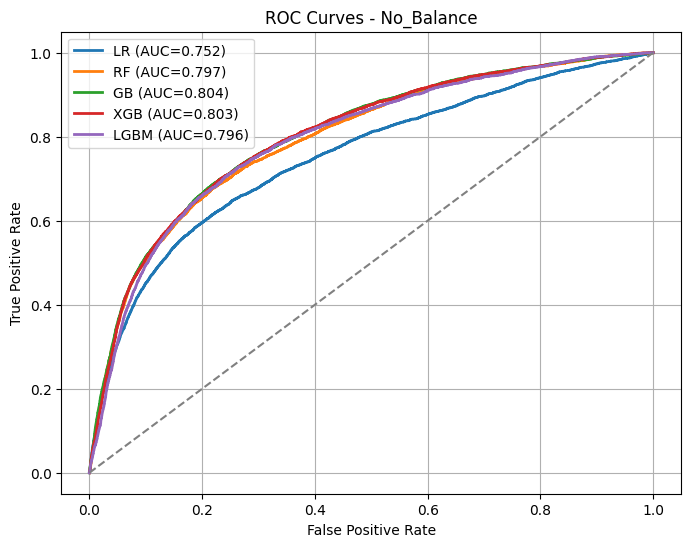

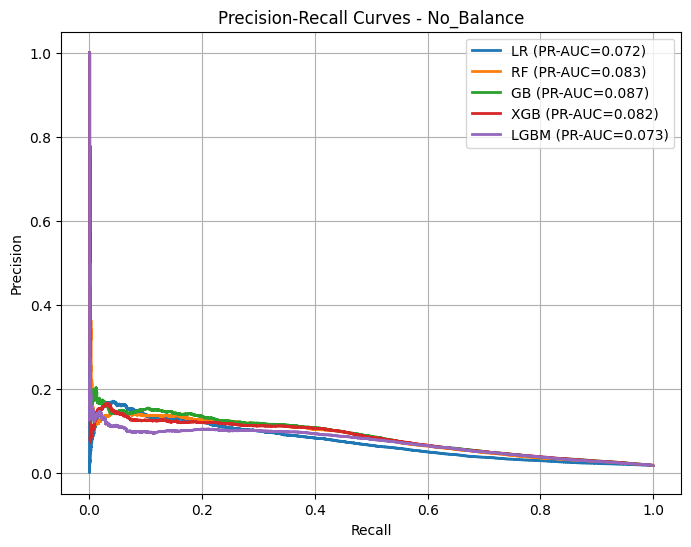

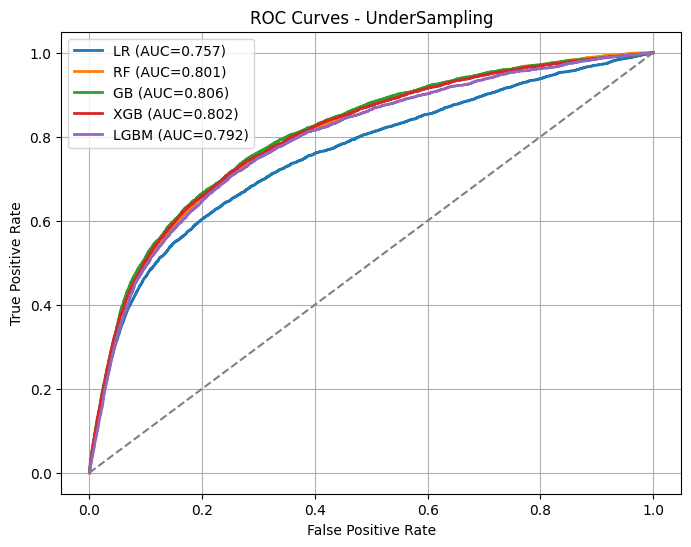

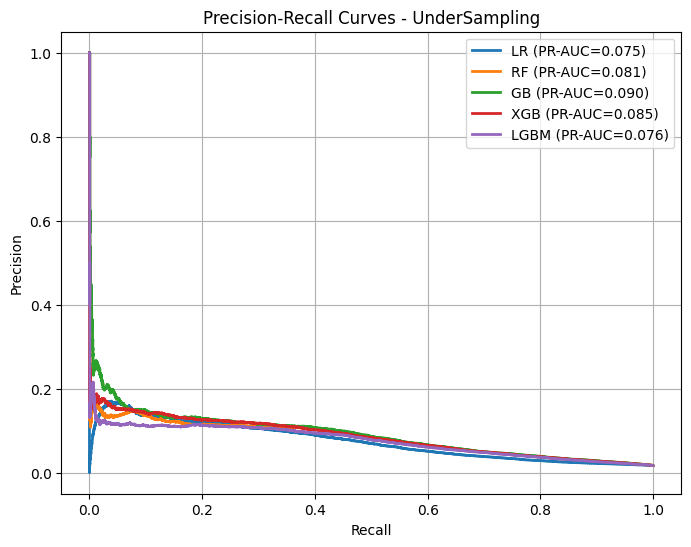

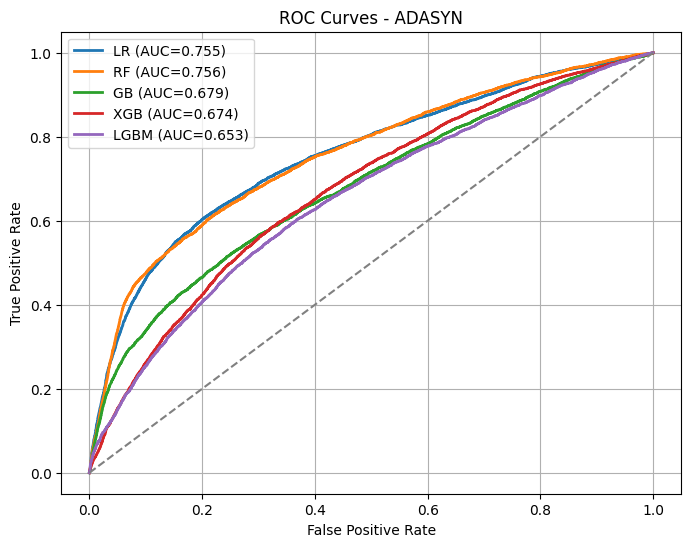

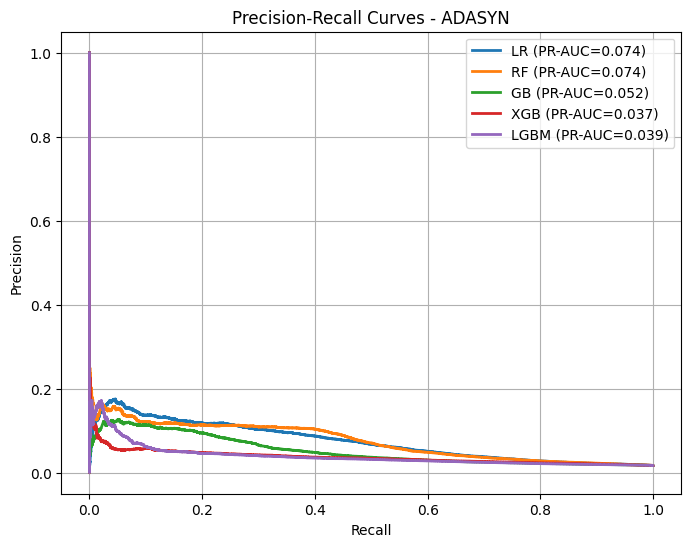

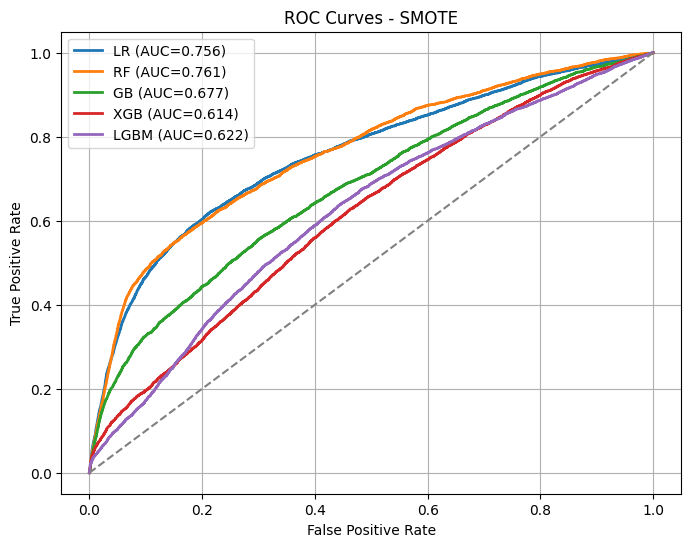

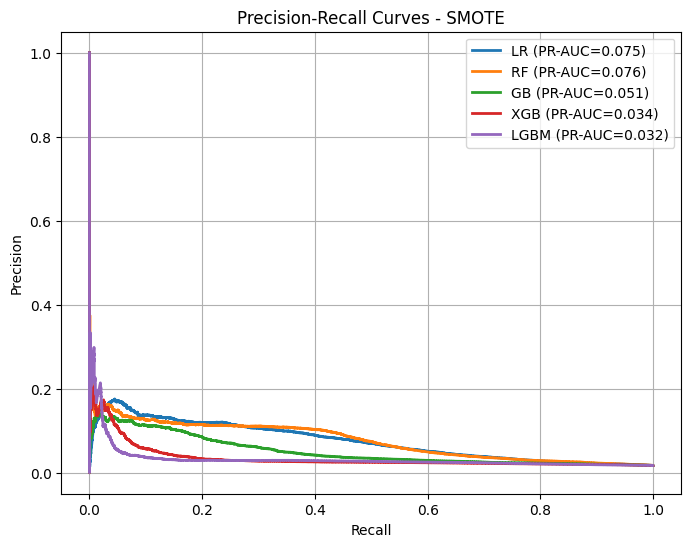

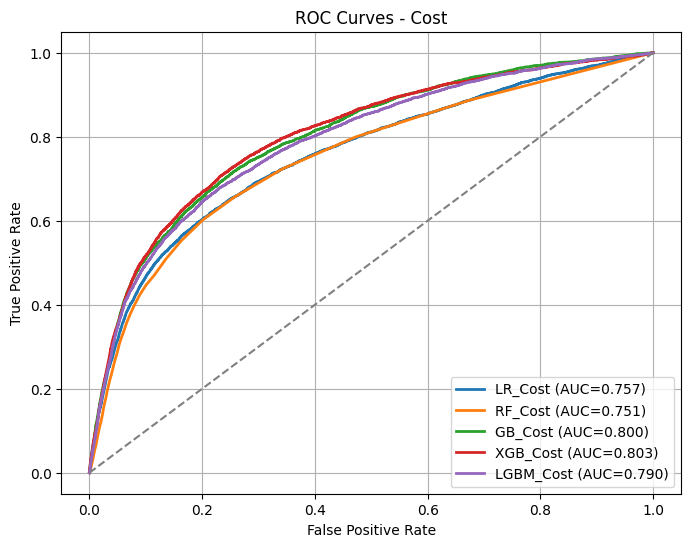

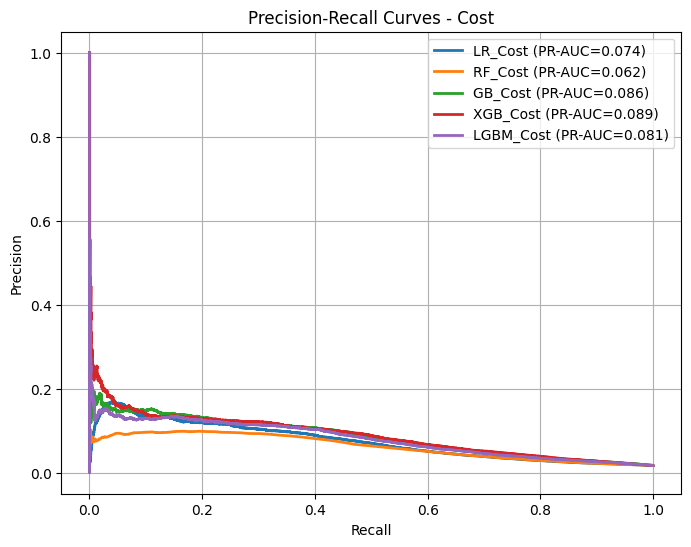

         Strategy      Model  Accuracy  ROC_AUC  PR_AUC  Best_Threshold  \
23           Cost   XGB_Cost    0.9479   0.8034  0.0889          0.8130   
7   UnderSampling         GB    0.9360   0.8059  0.0904          0.8010   
2      No_Balance         GB    0.9422   0.8038  0.0872          0.0841   
22           Cost    GB_Cost    0.9396   0.8000  0.0858          0.0820   
8   UnderSampling        XGB    0.9458   0.8019  0.0852          0.8267   
3      No_Balance        XGB    0.9356   0.8029  0.0817          0.0736   
1      No_Balance         RF    0.9426   0.7968  0.0832          0.0924   
24           Cost  LGBM_Cost    0.9434   0.7901  0.0806          0.8035   
6   UnderSampling         RF    0.9362   0.8012  0.0810          0.7902   
16          SMOTE         RF    0.9380   0.7614  0.0757          0.7540   
11         ADASYN         RF    0.9326   0.7558  0.0743          0.7026   
9   UnderSampling       LGBM    0.9411   0.7923  0.0758          0.8110   
15          SMOTE        

In [ ]:
models_list = ["LR","RF","GB","XGB","LGBM"]

all_threshold_results = []

for strategy in [
    "No_Balance",
    "UnderSampling",
    "ADASYN",
    "SMOTE"
]:

    plot_strategy_curves(
        strategy,
        models_list,
        X_test,
        y_test
    )

    temp = plot_strategy_pr(
        strategy,
        models_list,
        X_test,
        y_test
    )

    all_threshold_results.append(temp)

# Cost Models

cost_models = [
    "LR_Cost",
    "RF_Cost",
    "GB_Cost",
    "XGB_Cost",
    "LGBM_Cost"
]

plot_strategy_curves(
    "Cost",
    cost_models,
    X_test,
    y_test
)

temp = plot_strategy_pr(
    "Cost",
    cost_models,
    X_test,
    y_test
)

all_threshold_results.append(temp)

# Final Table

threshold_df = pd.concat(
    all_threshold_results,
    ignore_index=True
)

threshold_df = threshold_df.sort_values(
    by=["F1","ROC_AUC"],
    ascending=False
)

print(threshold_df)

threshold_df.to_csv(
    base_path + "/Threshold_Optimization_Results.csv",
    index=False
)

In [ ]:
#CI 95%
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import joblib

def bootstrap_auc_ci(model, X_test, y_test,
                     n_bootstraps=1000,
                     random_state=42):

    probs = model.predict_proba(X_test)[:,1]

    rng = np.random.RandomState(random_state)

    auc_scores = []

    for i in range(n_bootstraps):

        indices = rng.randint(
            0,
            len(y_test),
            len(y_test)
        )

        if len(np.unique(y_test.iloc[indices])) < 2:
            continue

        auc_score = roc_auc_score(
            y_test.iloc[indices],
            probs[indices]
        )

        auc_scores.append(auc_score)

    lower = np.percentile(auc_scores, 2.5)
    upper = np.percentile(auc_scores, 97.5)

    original_auc = roc_auc_score(
        y_test,
        probs
    )

    return original_auc, lower, upper

In [ ]:
ci_results = []

top_models = [
    ("Cost", "XGB_Cost"),
    ("UnderSampling", "GB"),
    ("UnderSampling", "RF")
]

for strategy, model_name in top_models:

    model_path = models_path + f"/{strategy}_{model_name}.pkl"

    model = joblib.load(model_path)

    auc_score, ci_low, ci_high = bootstrap_auc_ci(
        model,
        X_test,
        y_test
    )

    ci_results.append({

        "Strategy": strategy,
        "Model": model_name,
        "ROC_AUC": round(auc_score,4),
        "CI_Lower": round(ci_low,4),
        "CI_Upper": round(ci_high,4)

    })

ci_df = pd.DataFrame(ci_results)

print(ci_df)

        Strategy     Model  ROC_AUC  CI_Lower  CI_Upper
0           Cost  XGB_Cost   0.8034    0.7970    0.8102
1  UnderSampling        GB   0.8059    0.7995    0.8125
2  UnderSampling        RF   0.8012    0.7947    0.8072


In [ ]:
ci_df.to_csv(
    base_path + "/CI_Top3_Models.csv",
    index=False
)

print("CI results saved successfully")

CI results saved successfully


In [ ]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos = neg / pos

print("Negative samples:", neg)
print("Positive samples:", pos)
print("scale_pos =", scale_pos)

Negative samples: 822222
Positive samples: 15862
scale_pos = 51.835960156348506


Top 10 Features (CASE 1):
                 Feature  Importance
9                 ICULOS    0.245404
20          FiO2_missing    0.097211
32       Lactate_missing    0.061119
17         EtCO2_missing    0.047207
13           SBP_missing    0.034931
15           DBP_missing    0.026314
8            HospAdmTime    0.026275
14           MAP_missing    0.025607
1                     HR    0.023925
26  Alkalinephos_missing    0.023572


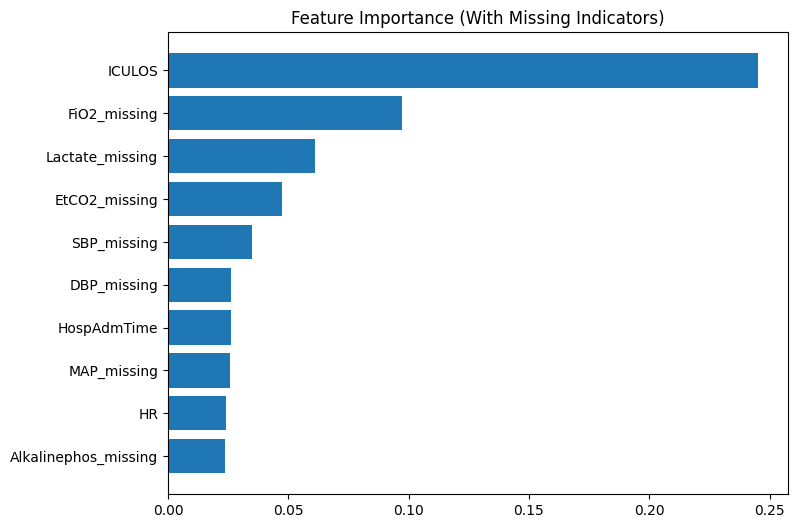

In [ ]:
#CASE 1 (WITH MISSING)
# ==========================================
# CASE 1: WITH MISSING INDICATORS
# ==========================================

import pandas as pd

best_model = model_cost_xgb
importances = best_model.feature_importances_

feat_imp_case1 = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Save Table (Table 6)
feat_imp_case1.to_csv(base_path + "/tables/feature_importance_case1.csv", index=False)

print("Top 10 Features (CASE 1):")
print(feat_imp_case1.head(10))

# Plot
plt.figure(figsize=(8,6))
plt.barh(feat_imp_case1["Feature"][:10], feat_imp_case1["Importance"][:10])
plt.gca().invert_yaxis()
plt.title("Feature Importance (With Missing Indicators)")
plt.savefig(base_path + "/figures/feature_importance_case1.png",dpi=300,
    bbox_inches="tight")

plt.savefig(
    base_path + "/figures/feature_importance_case1.pdf",
    bbox_inches="tight"
)
plt.show()

Top 10 Features (CASE 2):
       Feature  Importance
9       ICULOS    0.574787
8  HospAdmTime    0.063503
5         Resp    0.059525
1           HR    0.058540
6          Age    0.045119
7       Gender    0.044642
2        O2Sat    0.043608
4          MAP    0.042110
3          SBP    0.034562
0         Hour    0.033603


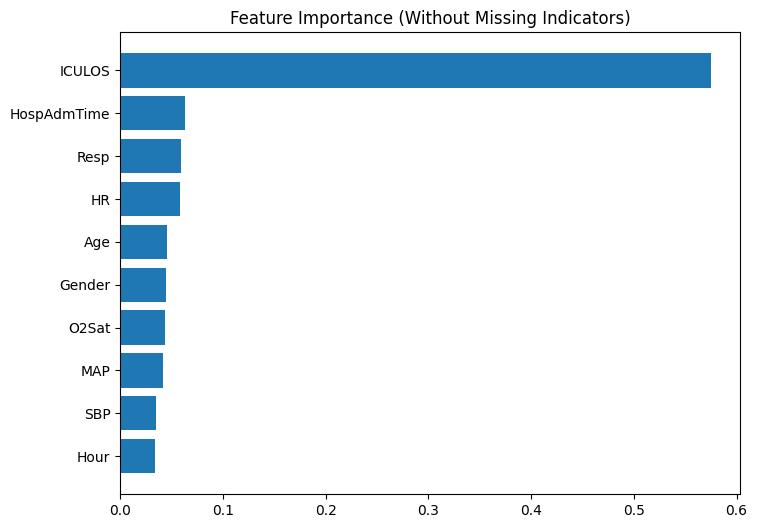

In [ ]:
# ==========================================
# CASE 2: WITHOUT MISSING INDICATORS
# ==========================================

# REMOVE MISSING COLUMNS
cols_to_drop = [col for col in X_train.columns if "_missing" in col]

X_train_nomiss = X_train.drop(columns=cols_to_drop)
X_test_nomiss = X_test.drop(columns=cols_to_drop)

# TRAIN SAME MODEL AGAIN
from xgboost import XGBClassifier

model_nomiss = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos,
    eval_metric='logloss',
    random_state=42
)

model_nomiss.fit(X_train_nomiss, y_train)

# FEATURE IMPORTANCE
importances2 = model_nomiss.feature_importances_

feat_imp_case2 = pd.DataFrame({
    "Feature": X_train_nomiss.columns,
    "Importance": importances2
}).sort_values(by="Importance", ascending=False)

# Save Table
feat_imp_case2.to_csv(base_path + "/tables/feature_importance_case2.csv", index=False)

print("Top 10 Features (CASE 2):")
print(feat_imp_case2.head(10))

# Plot
plt.figure(figsize=(8,6))
plt.barh(feat_imp_case2["Feature"][:10], feat_imp_case2["Importance"][:10])
plt.gca().invert_yaxis()
plt.title("Feature Importance (Without Missing Indicators)")
plt.savefig(base_path + "/figures/feature_importance_case2.png",dpi=300,
    bbox_inches="tight")

plt.savefig(
    base_path + "/figures/feature_importance_case2.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
#SHAP Analysis
!pip install shap -q

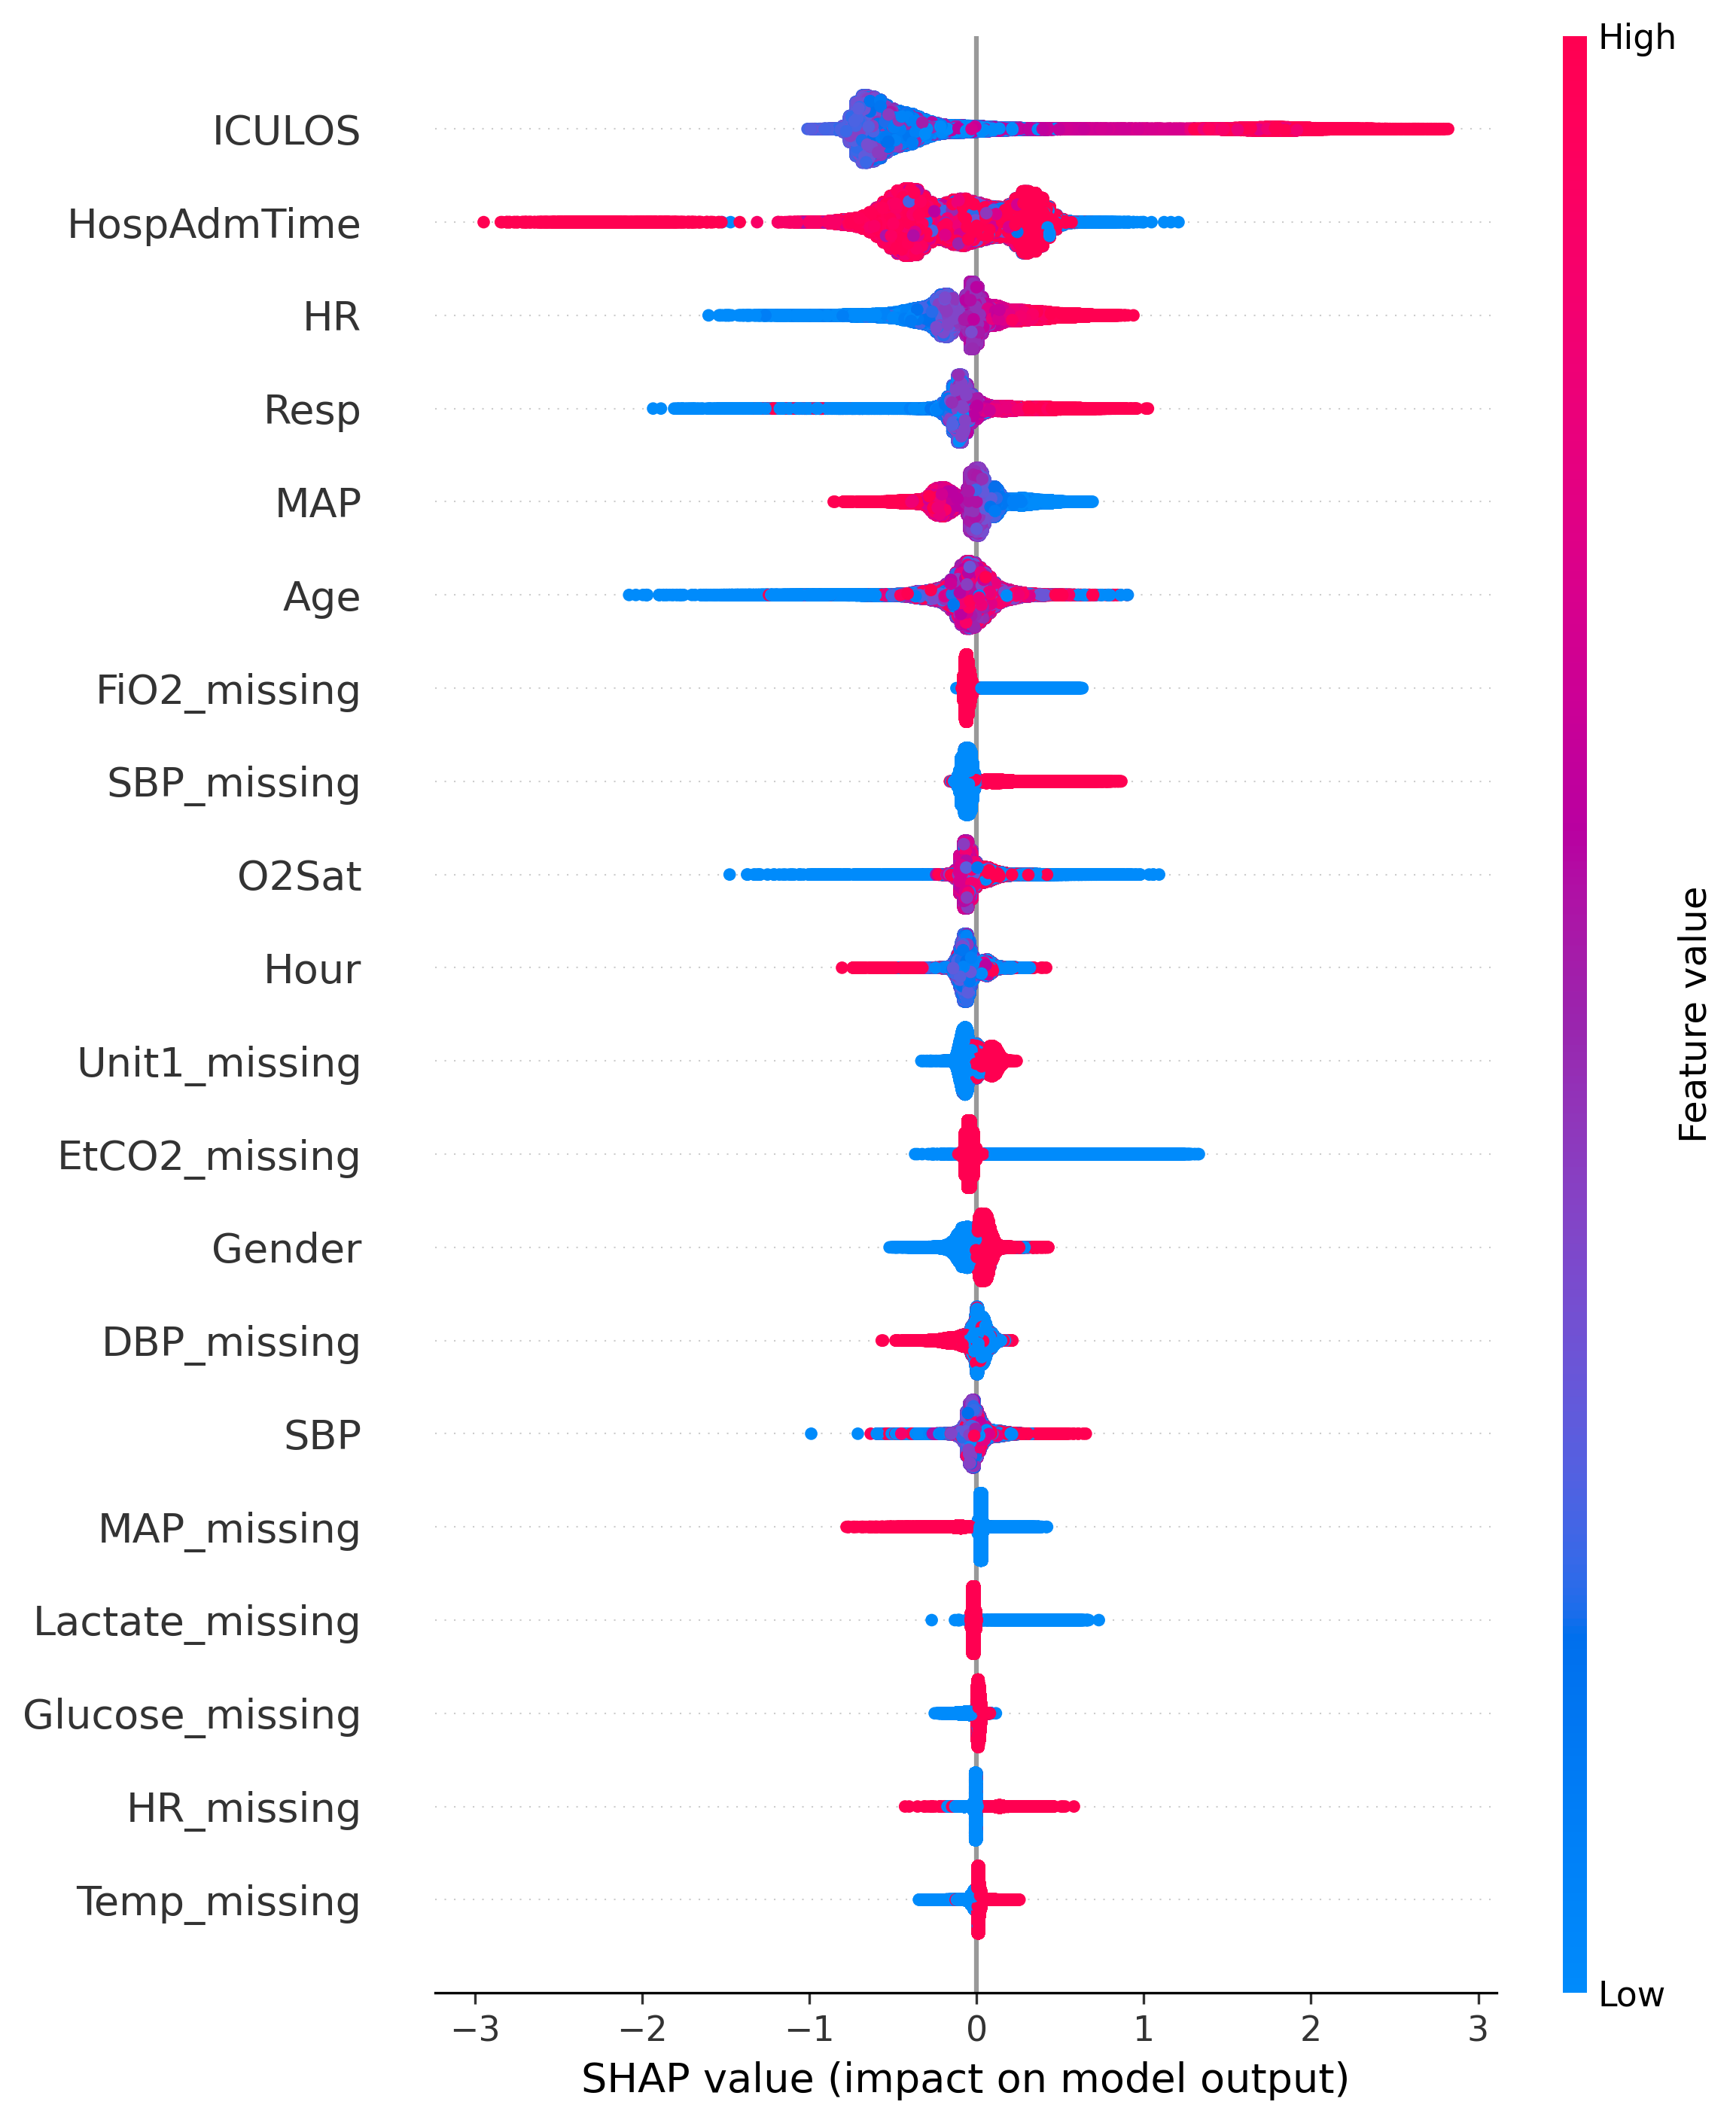

In [ ]:
#Summary Plot
import shap
import matplotlib.pyplot as plt

# =========================
# EXPLAINER
# =========================
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# =========================
# PLOT SETTINGS (IMPORTANT FOR QUALITY)
# =========================
plt.figure(figsize=(12, 8), dpi=300)

# SHAP summary plot (NO SHOW INSIDE)
shap.summary_plot(
    shap_values,
    X_test,
    show=False  # IMPORTANT
)

# =========================
# SAVE HIGH-QUALITY FIGURE
# =========================
plt.tight_layout()
plt.savefig(
    base_path + "/figures/shap_summary.png",
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    base_path + "/figures/shap_summary.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Force Plot (Correct vs Incorrect)
# pick one correct & one wrong prediction
preds = best_model.predict(X_test)

correct_idx = (preds == y_test).idxmax()
wrong_idx = (preds != y_test).idxmax()

# FORCE PLOTS
shap.initjs()

shap.force_plot(
    explainer.expected_value,
    shap_values[correct_idx],
    X_test.iloc[correct_idx]
)

shap.force_plot(
    explainer.expected_value,
    shap_values[wrong_idx],
    X_test.iloc[wrong_idx]
)

In [ ]:
print(correct_idx)
print(wrong_idx)

9718
9717


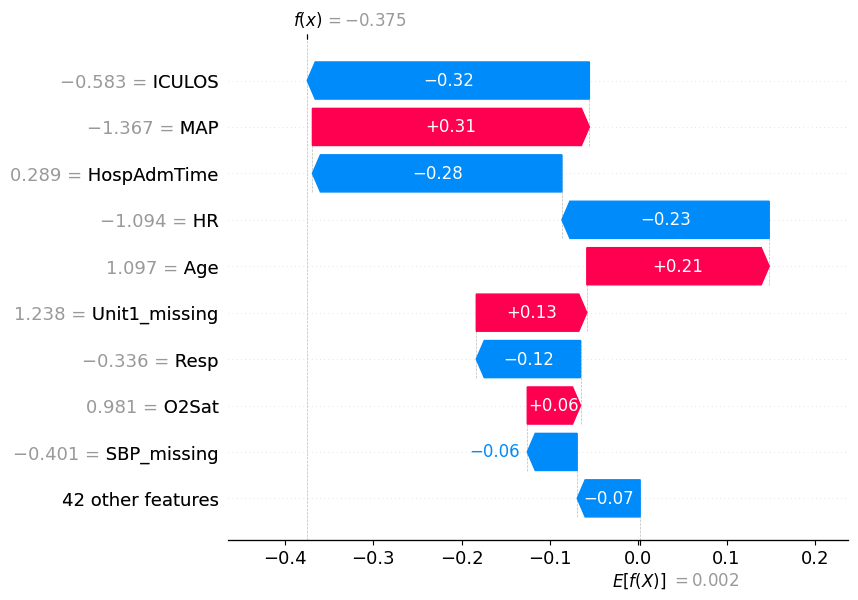

In [ ]:
import matplotlib.pyplot as plt

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[correct_idx],
        base_values=explainer.expected_value,
        data=X_test.iloc[correct_idx],
        feature_names=X_test.columns
    ),
    show=False
)

plt.savefig(
    base_path + "/figures/waterfall_correct.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    base_path + "/figures/waterfall_correct.pdf",
    bbox_inches="tight"
)
plt.show()

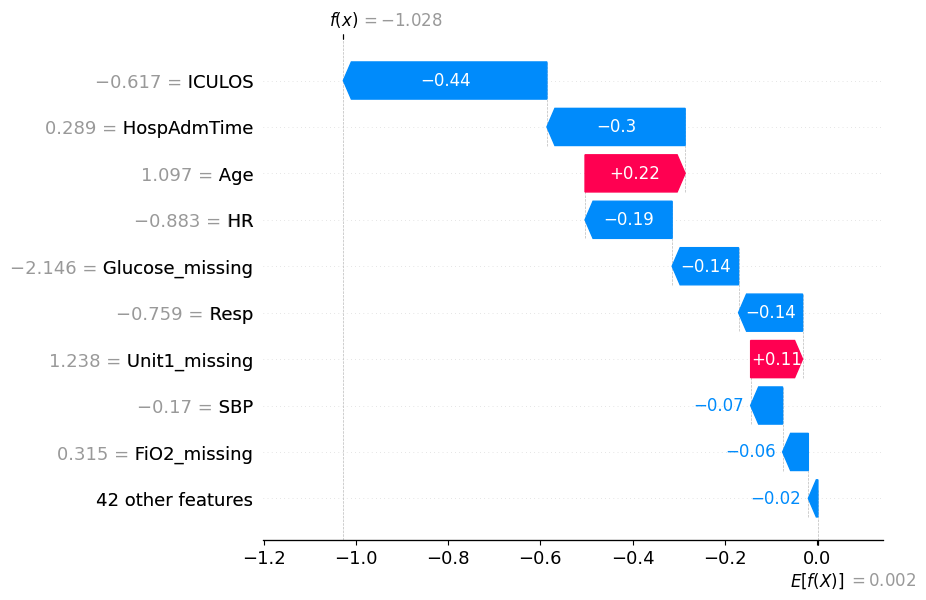

In [ ]:
#misclassified patient
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[wrong_idx],
        base_values=explainer.expected_value,
        data=X_test.iloc[wrong_idx],
        feature_names=X_test.columns
    ),
    show=False
)

plt.savefig(
    base_path + "/figures/waterfall_wrong.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    base_path + "/figures/waterfall_wrong.pdf",
    bbox_inches="tight"
)
plt.show()

In [ ]:
import shap

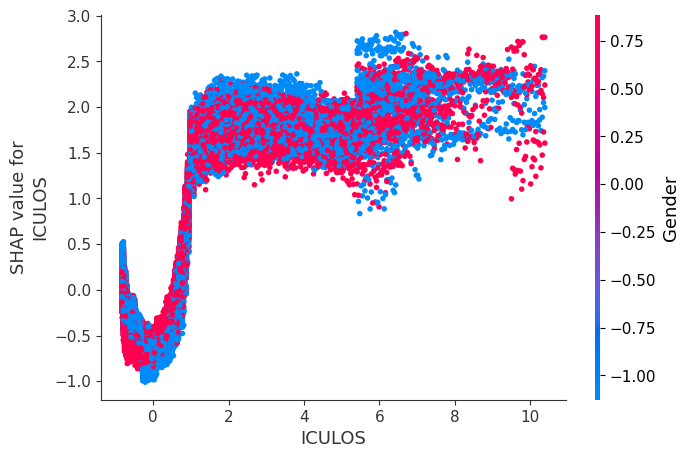

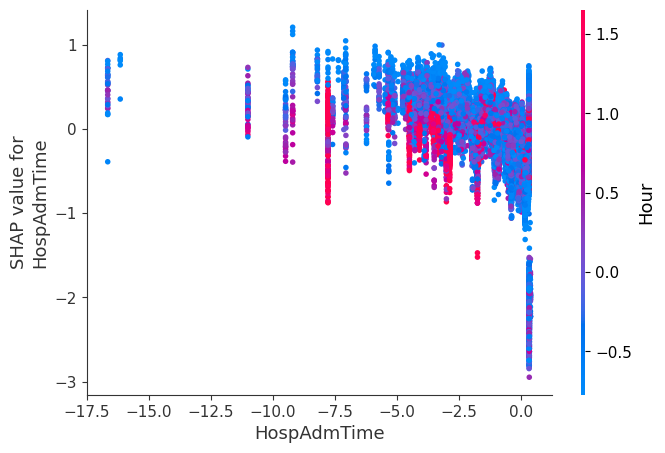

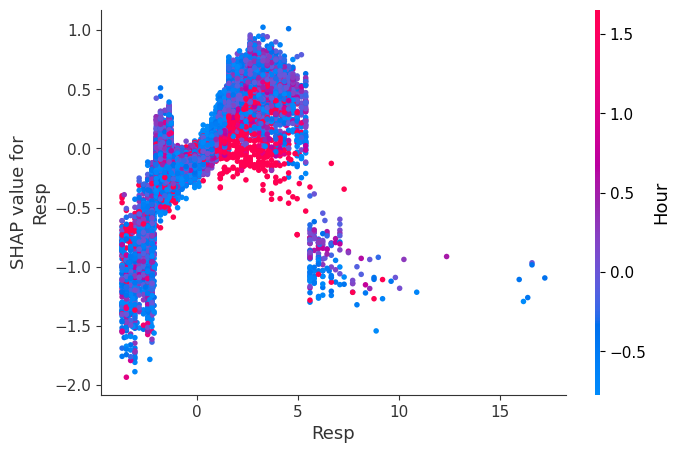

In [ ]:
#Dependency Plots (Top 3 Features)
top_features = ["ICULOS","HospAdmTime", "Resp"]

for f in top_features:
    if f in X_test.columns:
        shap.dependence_plot(f, shap_values, X_test,show=False)

        plt.savefig(base_path + f"/figures/shap_dependence_without_missing_{f}.png",
        dpi=300,
        bbox_inches="tight")
        plt.savefig(base_path + f"/figures/shap_dependence_without_missing_{f}.pdf",
        bbox_inches="tight")
        plt.show()
        plt.close()

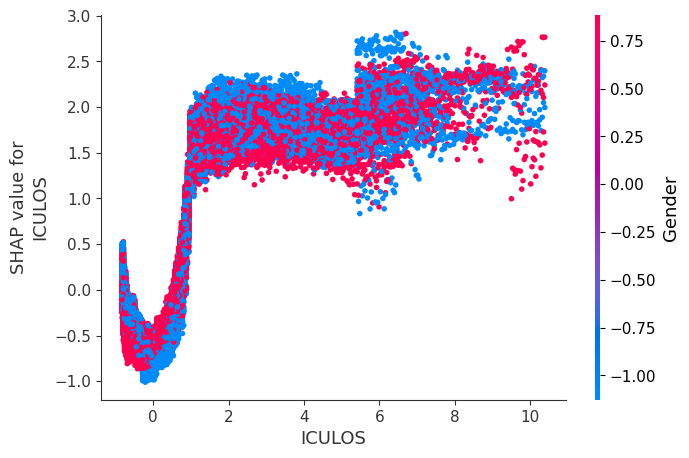

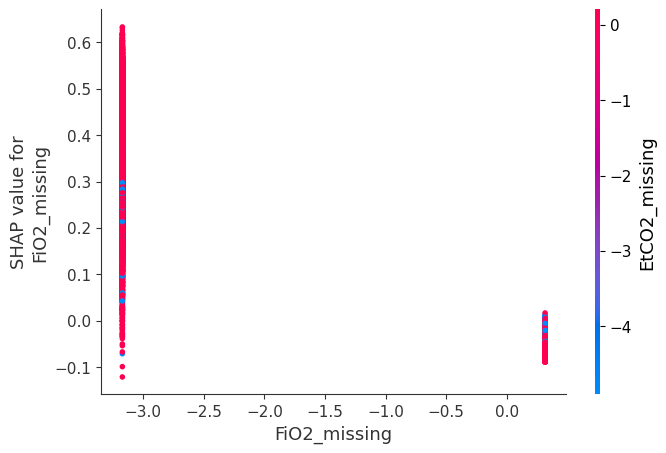

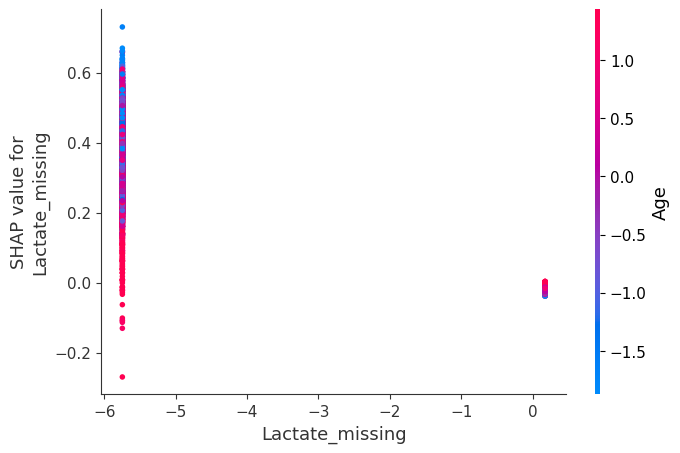

In [ ]:
#Dependency Plots (Top 3 Features)
top_features = ["ICULOS","FiO2_missing","Lactate_missing"]

for f in top_features:
    if f in X_test.columns:
        shap.dependence_plot(f, shap_values, X_test, show=False)
        plt.savefig(base_path + f"/figures/shap_dependence_with_missing_indicator{f}.png",dpi=300,bbox_inches="tight")
        plt.savefig(base_path + f"/figures/shap_dependence_without_missing_{f}.pdf",
    bbox_inches="tight")
        plt.show()
        plt.close()

In [ ]:
#TimeSeriesSplit (ADVANCED VALIDATION)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score

tscv = TimeSeriesSplit(n_splits=5)

auc_scores = []

for train_idx, test_idx in tscv.split(X_train):

    X_tr, X_te = X_train.iloc[train_idx], X_train.iloc[test_idx]
    y_tr, y_te = y_train.iloc[train_idx], y_train.iloc[test_idx]

    model = best_model
    model.fit(X_tr, y_tr)

    probs = model.predict_proba(X_te)[:,1]
    auc = roc_auc_score(y_te, probs)

    auc_scores.append(auc)

print("TimeSeries CV AUC:", auc_scores)
print("Mean AUC:", np.mean(auc_scores))

TimeSeries CV AUC: [np.float64(0.7964847456343296), np.float64(0.8211295216089073), np.float64(0.8369972012603606), np.float64(0.841269129220282), np.float64(0.847678569288805)]
Mean AUC: 0.8287118334025368


XGB Brier Score: 0.1496
GB Brier Score: 0.1709
RF Brier Score: 0.1738


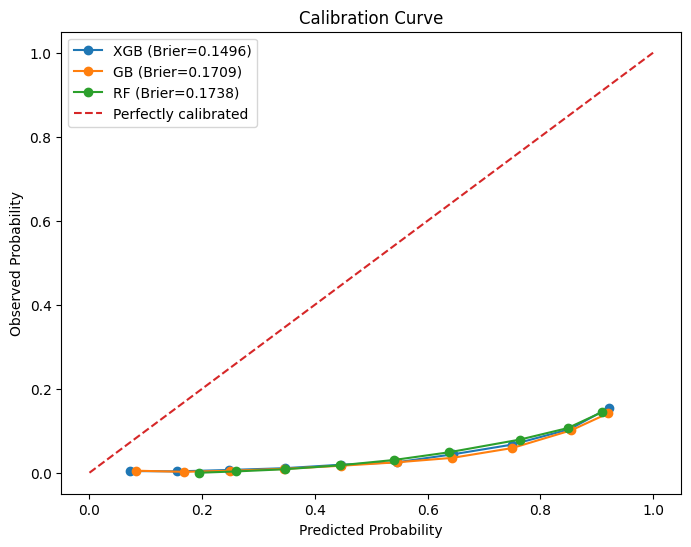

In [ ]:
#CALIBRATION ANALYSIS
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

models_to_check = {
    "XGB": model_cost_xgb,
    "GB": model_us_gb,
    "RF": model_us_rf
}

plt.figure(figsize=(8,6))

for name, model in models_to_check.items():

    probs = model.predict_proba(X_test)[:,1]

    # Calibration curve
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)



    # Brier score
    brier = brier_score_loss(y_test, probs)
    print(f"{name} Brier Score: {brier:.4f}")

     # Plot
    plt.plot(mean_pred, frac_pos, marker='o', label=f"{name} (Brier={brier:.4f})")

# Perfect line
plt.plot([0,1],[0,1],'--',label='Perfectly calibrated')

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Probability")
plt.title("Calibration Curve")
plt.legend()

plt.savefig(base_path + "/figures/Calibration curve.png",dpi=300,bbox_inches="tight")
plt.savefig(base_path + "/figures/Calibration curve.pdf",
    bbox_inches="tight")


plt.show()

In [ ]:
#Wilcoxon TEST — BEST FOR ML
from scipy.stats import wilcoxon

def get_predictions(model):
    return model.predict(X_test)

best_preds = get_predictions(model_xgb)

baselines = {
    "RF": model_rf,
    "LGBM": model_lgbm,
    "GB": model_gb
}

for name, model in baselines.items():

    preds = get_predictions(model)

    stat, p = wilcoxon(best_preds, preds)

    print(f"{name} vs XGB_Cost -> p-value: {p:.6f}")

RF vs XGB_Cost -> p-value: 0.000000
LGBM vs XGB_Cost -> p-value: 0.000000
GB vs XGB_Cost -> p-value: 0.000000


In [ ]:
from scipy.stats import wilcoxon

def compare_models(model_a, model_b, X_test, y_test, name_a, name_b):

    prob_a = model_a.predict_proba(X_test)[:,1]
    prob_b = model_b.predict_proba(X_test)[:,1]

    stat, p_value = wilcoxon(prob_a, prob_b)

    print(f"\n{name_a} vs {name_b}")
    print("p-value:", p_value)

    return p_value

In [ ]:
# Cost-sensitive XGB
best_model = model_cost_xgb

# Baselines
model1 = model_xgb
model2 = model_sm_XGB
model3 = model_ad_xgb
model4 = model_rf

In [ ]:
compare_models(best_model, model1, X_test, y_test, "Cost_XGB", "No_Balance_XGB")
compare_models(best_model, model2, X_test, y_test, "Cost_XGB", "SMOTE_XGB")
compare_models(best_model, model3, X_test, y_test, "Cost_XGB", "ADASYN_XGB")
compare_models(best_model, model4, X_test, y_test, "Cost_XGB", "No_Balance_RF")


Cost_XGB vs No_Balance_XGB
p-value: 0.0

Cost_XGB vs SMOTE_XGB
p-value: 0.0

Cost_XGB vs ADASYN_XGB
p-value: 0.0

Cost_XGB vs No_Balance_RF
p-value: 0.0


np.float64(0.0)

In [ ]:
compare_models(best_model, model1, X_test, y_test, "Cost_XGB", "SMOTE_RF")


Cost_XGB vs SMOTE_RF
p-value: 0.0


np.float64(0.0)

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix
)
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)

auc_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
specificity_scores = []
sensitivity_scores = []

for train_idx, test_idx in tscv.split(X_train):

    X_tr, X_te = X_train.iloc[train_idx], X_train.iloc[test_idx]
    y_tr, y_te = y_train.iloc[train_idx], y_train.iloc[test_idx]

    model = best_model
    model.fit(X_tr, y_tr)

    probs = model.predict_proba(X_te)[:,1]
    preds = model.predict(X_te)

    # AUC
    auc_scores.append(roc_auc_score(y_te, probs))

    # Precision / Recall / F1
    precision_scores.append(precision_score(y_te, preds, zero_division=0))
    recall_scores.append(recall_score(y_te, preds, zero_division=0))
    f1_scores.append(f1_score(y_te, preds, zero_division=0))

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(y_te, preds).ravel()

    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)

    specificity_scores.append(specificity)
    sensitivity_scores.append(sensitivity)

print("===== TimeSeries CV Results =====")
print("AUC:", auc_scores)
print("Mean AUC:", np.mean(auc_scores))

print("Precision:", np.mean(precision_scores))
print("Recall:", np.mean(recall_scores))
print("F1:", np.mean(f1_scores))
print("Specificity:", np.mean(specificity_scores))
print("Sensitivity:", np.mean(sensitivity_scores))

===== TimeSeries CV Results =====
AUC: [np.float64(0.7964847456343296), np.float64(0.8211295216089073), np.float64(0.8369972012603606), np.float64(0.841269129220282), np.float64(0.847678569288805)]
Mean AUC: 0.8287118334025368
Precision: 0.07234553820197628
Recall: 0.6551472307097803
F1: 0.1302460248917222
Specificity: 0.8387201176289514
Sensitivity: 0.6551472307097803


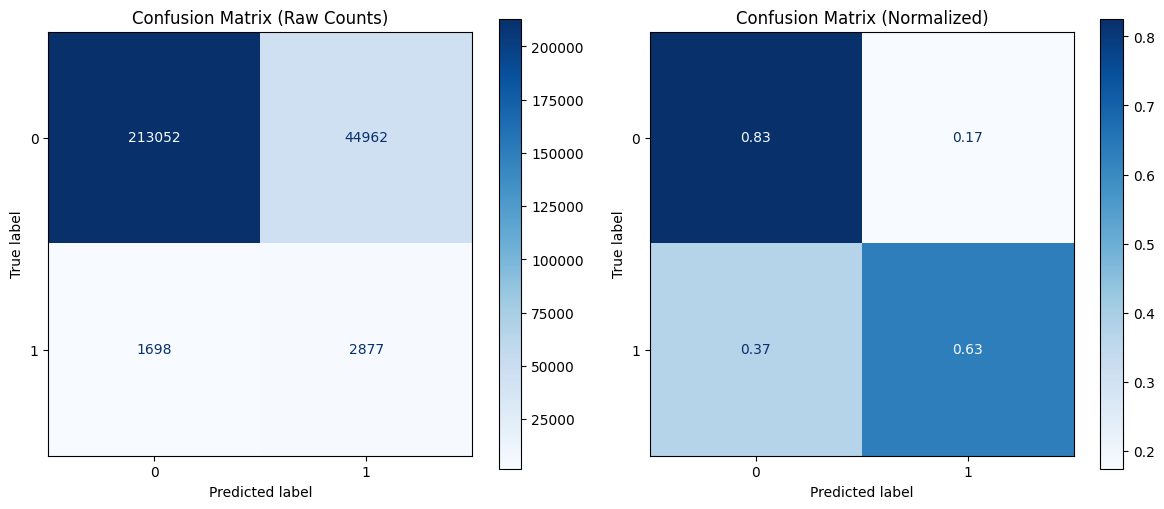

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# predictions
y_pred = best_model.predict(X_test)

# raw confusion matrix
cm = confusion_matrix(y_test, y_pred)

# normalized confusion matrix (row-wise)
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# ======================
# RAW COUNTS
# ======================
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm)
disp1.plot(ax=ax[0], cmap='Blues', values_format='d')
ax[0].set_title("Confusion Matrix (Raw Counts)")

# ======================
# NORMALIZED
# ======================
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm)
disp2.plot(ax=ax[1], cmap='Blues', values_format='.2f')
ax[1].set_title("Confusion Matrix (Normalized)")

plt.tight_layout()
plt.savefig(base_path + "/figures/confusion_matrix_best_model.png", dpi=300)
plt.show()

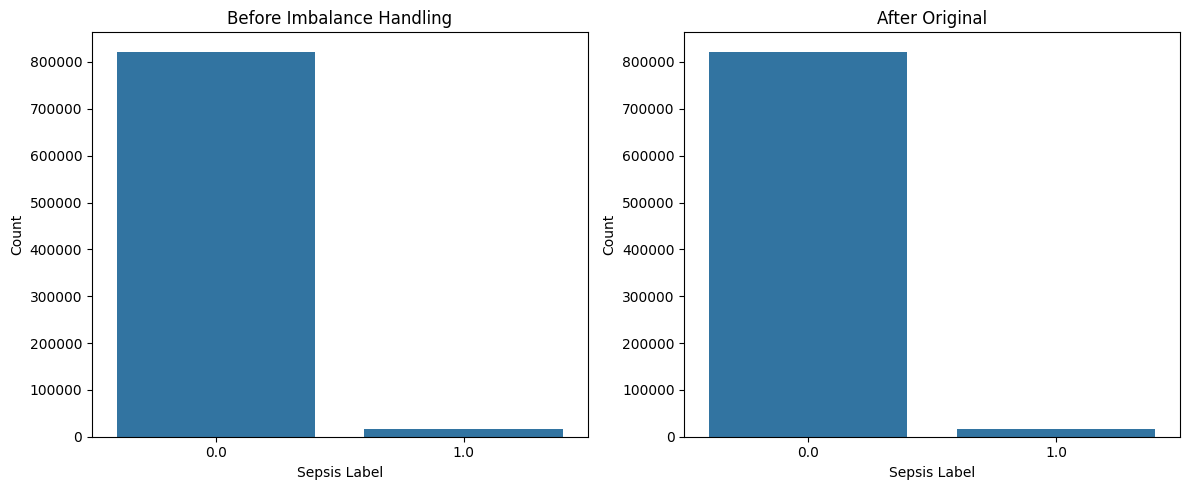

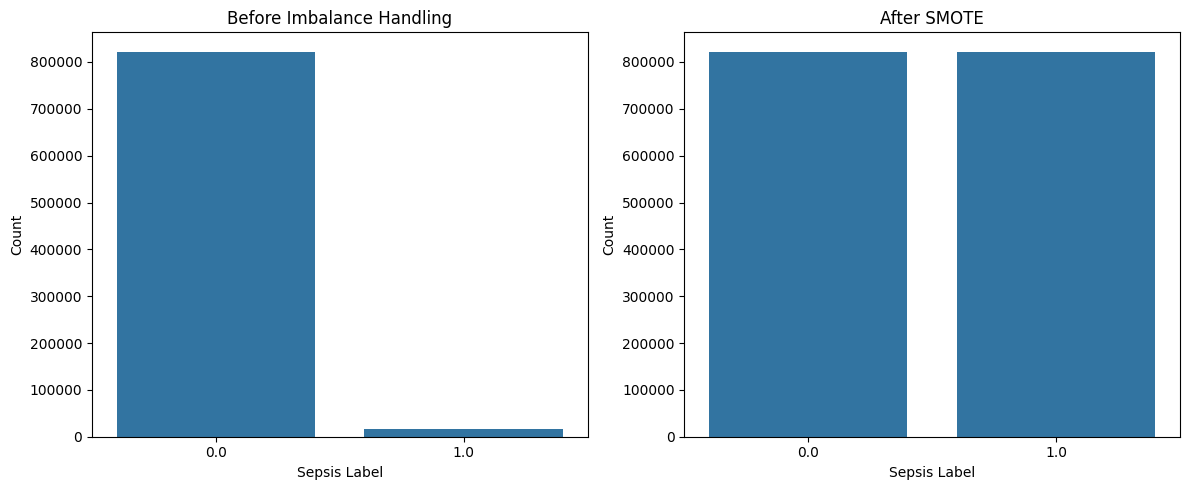

In [ ]:
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)

plot_class_distribution(y_train, y_sm, "SMOTE")

In [ ]:
# ==========================================
# 4.X ABLATION STUDY
# ==========================================

In [ ]:
#Missing indicators identify
# ==========================================
# IDENTIFY MISSING INDICATOR FEATURES
# ==========================================

cols_to_drop = [
    col for col in X_train.columns
    if "_missing" in col
]

print("Missing Indicator Features:")
for col in cols_to_drop:
    print(col)

print("\nTotal Missing Indicators:", len(cols_to_drop))

Missing Indicator Features:
HR_missing
O2Sat_missing
Temp_missing
SBP_missing
MAP_missing
DBP_missing
Resp_missing
EtCO2_missing
BaseExcess_missing
HCO3_missing
FiO2_missing
pH_missing
PaCO2_missing
SaO2_missing
AST_missing
BUN_missing
Alkalinephos_missing
Calcium_missing
Chloride_missing
Creatinine_missing
Bilirubin_direct_missing
Glucose_missing
Lactate_missing
Magnesium_missing
Phosphate_missing
Potassium_missing
Bilirubin_total_missing
TroponinI_missing
Hct_missing
Hgb_missing
PTT_missing
WBC_missing
Fibrinogen_missing
Platelets_missing
Unit1_missing
Unit2_missing

Total Missing Indicators: 36


In [ ]:
# ==========================================
# REMOVE MISSING INDICATORS
# ==========================================

X_train_nomiss = X_train.drop(columns=cols_to_drop)
X_test_nomiss = X_test.drop(columns=cols_to_drop)

print("Original Shape:", X_train.shape)
print("Without Missing Indicators:", X_train_nomiss.shape)

Original Shape: (838084, 51)
Without Missing Indicators: (838084, 15)


In [ ]:
print("Removed Features:", len(cols_to_drop))
print(cols_to_drop)

Removed Features: 36
['HR_missing', 'O2Sat_missing', 'Temp_missing', 'SBP_missing', 'MAP_missing', 'DBP_missing', 'Resp_missing', 'EtCO2_missing', 'BaseExcess_missing', 'HCO3_missing', 'FiO2_missing', 'pH_missing', 'PaCO2_missing', 'SaO2_missing', 'AST_missing', 'BUN_missing', 'Alkalinephos_missing', 'Calcium_missing', 'Chloride_missing', 'Creatinine_missing', 'Bilirubin_direct_missing', 'Glucose_missing', 'Lactate_missing', 'Magnesium_missing', 'Phosphate_missing', 'Potassium_missing', 'Bilirubin_total_missing', 'TroponinI_missing', 'Hct_missing', 'Hgb_missing', 'PTT_missing', 'WBC_missing', 'Fibrinogen_missing', 'Platelets_missing', 'Unit1_missing', 'Unit2_missing']


In [ ]:
#. Calculate scale_pos

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos = neg / pos

In [ ]:
#SAME XGB_Cost Model
from xgboost import XGBClassifier

model_nomiss = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos,
    eval_metric='logloss',
    random_state=42
)

model_nomiss.fit(
    X_train_nomiss,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
#Evaluate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

y_prob = model_nomiss.predict_proba(X_test_nomiss)[:,1]
y_pred = model_nomiss.predict(X_test_nomiss)

acc = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred,zero_division=0)
recall = recall_score(y_test,y_pred,zero_division=0)
f1 = f1_score(y_test,y_pred,zero_division=0)

roc_auc = roc_auc_score(y_test,y_prob)
pr_auc = average_precision_score(y_test,y_prob)


In [ ]:
#THRESHOLD OPT FOR model without missing indicator

from sklearn.metrics import precision_recall_curve
import numpy as np

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

f1_scores = (
    2 * precision_curve[:-1] * recall_curve[:-1]
) / (
    precision_curve[:-1] + recall_curve[:-1] + 1e-10
)

best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]

print("Best Threshold =", round(best_threshold,4))

Best Threshold = 0.7752


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred_opt = (
    y_prob >= best_threshold
).astype(int)

acc_opt = accuracy_score(y_test, y_pred_opt)

precision_opt = precision_score(
    y_test,
    y_pred_opt,
    zero_division=0
)

recall_opt = recall_score(
    y_test,
    y_pred_opt,
    zero_division=0
)

f1_opt = f1_score(
    y_test,
    y_pred_opt,
    zero_division=0
)

print("Accuracy =", round(acc_opt,4))
print("Precision =", round(precision_opt,4))
print("Recall =", round(recall_opt,4))
print("F1 =", round(f1_opt,4))

Accuracy = 0.9386
Precision = 0.1083
Recall = 0.3486
F1 = 0.1652


In [ ]:
ablation_df = pd.DataFrame({

    "Configuration":[
        "XGB_Cost + Missing Indicators",
        "XGB_Cost Without Missing Indicators"
    ],

    "Accuracy":[
        0.9479,
        round(acc_opt,4)
    ],

    "ROC_AUC":[
        0.8034,
        round(roc_auc,4)
    ],

    "PR_AUC":[
        0.0889,
        round(pr_auc,4)
    ],

    "Recall":[
        0.3145,
        round(recall_opt,4)
    ],

    "F1":[
        0.1739,
        round(f1_opt,4)
    ]
})

print(ablation_df)

                         Configuration  Accuracy  ROC_AUC  PR_AUC  Recall  \
0        XGB_Cost + Missing Indicators    0.9479   0.8034  0.0889  0.3145   
1  XGB_Cost Without Missing Indicators    0.9386   0.7791  0.0839  0.3486   

       F1  
0  0.1739  
1  0.1652  


In [ ]:
# ============================================
# COHEN'S h EFFECT SIZE
# ============================================

import numpy as np
import pandas as pd

# Cohen's h function
def cohens_h(p1, p2):

    p1 = np.clip(p1, 1e-10, 1-1e-10)
    p2 = np.clip(p2, 1e-10, 1-1e-10)

    h = 2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2))

    return abs(h)


# ============================================
# Recall values from your final results
# ============================================

results = [

    ("Cost XGB", 0.3145),
    ("UnderSampling GB", 0.3803),
    ("UnderSampling RF", 0.3681),
    ("LSTM Cost", 0.4449),
    ("LSTM No Balance", 0.4404)

]

baseline = ("No Balance LR", 0.2083)

effect_results = []

for model, recall in results:

    h = cohens_h(recall, baseline[1])

    effect_results.append({

        "Compared Model": model,
        "Baseline": baseline[0],
        "Recall_Model": round(recall,4),
        "Recall_Baseline": baseline[1],
        "Cohens_h": round(h,4)

    })

effect_df = pd.DataFrame(effect_results)

print(effect_df)

effect_df.to_csv(
    base_path + "/tables/Cohens_h.csv",
    index=False
)

print("Saved Successfully.")

     Compared Model       Baseline  Recall_Model  Recall_Baseline  Cohens_h
0          Cost XGB  No Balance LR        0.3145           0.2083    0.2428
1  UnderSampling GB  No Balance LR        0.3803           0.2083    0.3812
2  UnderSampling RF  No Balance LR        0.3681           0.2083    0.3559
3         LSTM Cost  No Balance LR        0.4449           0.2083    0.5125
4   LSTM No Balance  No Balance LR        0.4404           0.2083    0.5034
Saved Successfully.


In [ ]:
import numpy as np
import pandas as pd

# Cohen's h function
def cohens_h(p1, p2):
    return abs(2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2)))

# Recall values from final results
comparisons = [

    ("Cost XGB",           0.3145, "UnderSampling GB", 0.3803),
    ("Cost XGB",           0.3145, "UnderSampling RF", 0.3681),
    ("Cost XGB",           0.3145, "Cost LSTM",        0.4449),
    ("Cost XGB",           0.3145, "No Balance LSTM",  0.4404)

]

results=[]

for m1,r1,m2,r2 in comparisons:

    h = cohens_h(r1,r2)

    if h < 0.20:
        interpretation="Small"

    elif h < 0.50:
        interpretation="Medium"

    else:
        interpretation="Large"

    results.append({

        "Model 1":m1,
        "Model 2":m2,
        "Recall 1":r1,
        "Recall 2":r2,
        "Cohen's h":round(h,3),
        "Interpretation":interpretation

    })

effect_df=pd.DataFrame(results)

print(effect_df)

effect_df.to_csv(
    base_path+"/tables/Cohens_h.csv",
    index=False
)

    Model 1           Model 2  Recall 1  Recall 2  Cohen's h Interpretation
0  Cost XGB  UnderSampling GB    0.3145    0.3803      0.138          Small
1  Cost XGB  UnderSampling RF    0.3145    0.3681      0.113          Small
2  Cost XGB         Cost LSTM    0.3145    0.4449      0.270         Medium
3  Cost XGB   No Balance LSTM    0.3145    0.4404      0.261         Medium
